# Планирование (продолжение)

## Планирование в момент принятия решений
>Планирование можно использовать по меньшей мере двумя способами. Ранее в этой главе мы рассмотрели подход, типичными представителями которого являются динамическое программирование и Dyna. При таком использовании планирование не сфокусировано на текущем состоянии и называется **<font color='orange'>фоновым планированием</font>**.

**<font color='orange'>Еще один способ</font>** использования планирования – **<font color='orange'>начать и закончить его после встречи нового состояния $S_t$, рассматривая как вычисление, результатом которого является выбор одного действия $A_t$</font>**; на следующем шаге планирование начинается заново для состояния $S_{t+1}$ и порождает состояние $A_{t+1}$. И так далее. Простейший, почти вырожденный **<font color='orange'>пример</font>** такого использования планирования возникает, когда **<font color='orange'>доступны только ценности состояний, а действие выбирается путем сравнения ценностей предсказанных моделью следующих состояний для каждого действия</font>**. В общем случае планирование, используемое таким образом, может оказаться гораздо глубже, чем заглядывание на один шаг вперед; **<font color='orange'>можно оценивать выбор действий, приводящих ко многим различным предсказанным состояниям и траекториям вознаграждения</font>**. В отличие от первого способа, здесь планирование сфокусировано **<font color='orange'>на конкретном состоянии</font>**. Это **<font color='orange'>планирование в момент принятия решений</font>**.

## Эвристический поиск
>Классические методы планирования в пространстве состояний, применяемые в области искусственного интеллекта, относятся к методам планирования в момент принятия решений и в совокупности известны под названием **<font color='orange'>эвристический поиск</font>**.

В эвристическом поиске **<font color='orange'>для каждого встретившегося состояния</font>** рассматривается **<font color='orange'>большое дерево возможных продолжений</font>**. **<font color='orange'>К листовым узлам применяется приближенная функция ценности</font>**, а затем **<font color='orange'>производится обновление текущего состояния в корне</font>**. Процесс обновления в дереве поиска такой же, как процесс **<font color='orange'>полного max-обновления</font>** (для функций $v^*$ и $q^*$). **<font color='orange'>Обновление останавливается в узлах $(s,a)$, относящихся к текущему состоянию</font>**. После того как обновленные ценности этих узлов вычислены, **<font color='orange'>лучшее из них выбирается в качестве текущего действия</font>**, а все **<font color='orange'>остальные</font>** обновленные ценности **<font color='orange'>отбрасываются</font>**.

Но ведь **<font color='orange'>можно смотреть и далее одного шага</font>**. Смысл такого поиска с заглядыванием далее, чем на один шаг, заключается в том, чтобы **<font color='orange'>более эффективно выбирать действия</font>**. Если имеется идеальная модель и неидеальная функция ценности действий, то более глубокий поиск обычно находит более эффективные стратегии. Очевидно, что **<font color='orange'>если поиск осуществляется до самого конца эпизода, то последствия неидеальности функции ценности устраняются, и определенное таким образом действие должно быть оптимальным</font>**. С другой стороны, **<font color='orange'>чем глубже поиск, тем больше объем вычислений</font>**, и обычно это приводит к увеличению времени отклика.

Хороший **<font color='orange'>пример</font>** – разработанная Тезауро программа TD-Gammon для игры в нарды на уровне гроссмейстера. В этой системе использовалось **<font color='orange'>TD-обучение для нахождения функции ценности послесостояний</font>**. Для этого программа сыграла много игр сама с собой, применяя **<font color='orange'>эвристический поиск хороших ходов</font>**. В качестве модели в TD-Gammon использовались **<font color='orange'>априорные знания о вероятностях выпадения комбинаций на костях</font>** и **<font color='orange'>предположение</font>** о том, **<font color='orange'>что противник всегда выбирает действия</font>**, которые TD-Gammon оценила бы как **<font color='orange'>наилучшие</font>**.

Тезауро обнаружил, что **<font color='orange'>чем глубже эвристический поиск, тем лучше ходы</font>**, найденные TD-Gammon, но и **<font color='orange'>тем больше времени требуется для каждого хода</font>**. Для игры в нарды характерен большой коэффициент ветвления, но на ход все равно отводится не более нескольких секунд. Практически осуществимым оказалось заглядывание вперед всего на несколько шагов, а не до конца эпизода, но **<font color='orange'>даже такой поиск позволил значительно улучшить алгоритм выбора действий</font>**.

**<font color='orange'>Самый очевидный способ</font>** сфокусировать обновления в эвристическом поиске: **<font color='orange'>на текущем состоянии и его преемниках</font>**. В **<font color='orange'>предельном случае</font>** мы могли бы использовать сами методы эвристического поиска **<font color='orange'>для построения дерева поиска</font>**, а затем выполнить индивидуальные **<font color='orange'>одношаговые обновления снизу вверх</font>**.

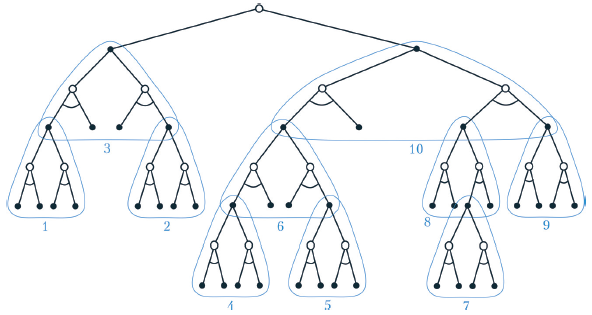

Эвристический поиск можно реализовать как **<font color='orange'>последовательность одношаговых обновлений</font>** (показаны синими линиями), **<font color='orange'>поднимающих ценности от листовых узлов к корню</font>**. Показанный на рисунке порядок соответствует **<font color='orange'>избирательному поиску в глубину</font>**. Выделяя большую часть вычислительных ресурсов **<font color='orange'>для обработки наиболее перспективных действий</font>**, планирование в момент принятия решений может находить лучшие решения, чем при бессистемном обновлении.

## Разыгрывающие алгоритмы
>**<font color='orange'>Разыгрывающие алгоритмы (rollout algorithm)</font>** – это алгоритмы планирования в момент принятия решений, основанные на **<font color='orange'>управлении методом Монте-Карло</font>**, применяемым к **<font color='orange'>имитированным траекториям</font>**, которые начинаются в **<font color='orange'>текущем состоянии окружающей среды</font>**.

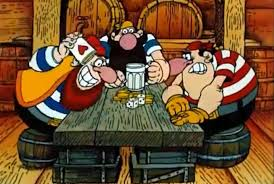

По факту, это **<font color='orange'>эвристический поиск</font>** - строим много имитированных траекторий от каждого возможного действия в конкретном состоянии, следуя посе этого **<font color='orange'>заданной стратегии</font>**. Когда считается, что оценки ценности действий достаточно точны, в планировании **<font color='orange'>выбирается наиболее перспективное</font>** из этих возможных действий. Далее продолжаем **<font color='orange'>в этом новом полученном состоянии</font>**, если есть еще время на планирование.


Как объяснено в работе Тезауро и Гальперина (Tesauro and Galperin, 1997), которые экспериментировали с разыгрывающими алгоритмами для игры в нарды, сам **<font color='orange'>термин «разыгрывающий»</font>** (rollout) **<font color='orange'>связан с тем</font>**, что **<font color='orange'>оценка ценности позиции в нардах производится путем многократного «разыгрывания» этой позиции до конца игры со случайно сгенерированными последовательностями бросания костей</font>**, когда оба игрока делают ходы, **<font color='orange'>следуя некоторой фиксированной стратегии</font>**.

В отличие от стандартного алгоритма управления МК, **<font color='orange'>цель разыгрывающего алгоритма</font>** – не оценить целиком оптимальную функцию ценности действий $q^*$ или функцию действий $q_π$ для заданной стратегии $π$, а **<font color='orange'>вычислить оценки МК только ценностей действий для каждого текущего состояния и для заданной стратегии</font>**, которая обычно называется **<font color='orange'>стратегией разыгрывания</font>**. Будучи алгоритмами **<font color='orange'>планирования в момент принятий решений</font>**, разыгрывающие алгоритмы **<font color='orange'>используют</font>** найденные оценки ценностей действий **<font color='orange'>и тут же отбрасывают их</font>**. Поэтому их довольно просто реализовать, т. к. нет необходимости производить выборку результатов для каждой пары $(s,a)$ и не нужно аппроксимировать функцию на пространстве состояний или $(s,a)$.

Но чего же тогда позволяют достичь разыгрывающие алгоритмы? **<font color='orange'>Цель разыгрывающего алгоритма – улучшение стратегии разыгрывания</font>**, а не нахождение оптимальной стратегии. Опыт показывает, что разыгрывающие алгоритмы могут быть на удивление эффективны. В некоторых приложениях разыгрывающий алгоритм может показывать хорошие результаты, даже если стратегия разыгрывания абсолютно случайна. Но **<font color='orange'>качество улучшенной стратегии зависит от свойств стратегии разыгрывания и ранжирования действий</font>**, порождаемых с помощью оценок ценности по методу МК. Интуиция подсказывает, что **<font color='orange'>чем лучше стратегия разыгрывания и чем точнее оценки ценности</font>**, **<font color='orange'>тем лучше</font>**, скорее всего, будет **<font color='orange'>стратегия</font>**, выработанная разыгрывающим алгоритмом.

Тут присутствуют важные **<font color='orange'>компромиссы</font>**, потому что для выработки лучшей стратегии разыгрывания обычно необходимо потратить больше времени для имитации траекторий в достаточном количестве, чтобы получить хорошие оценки ценности. Будучи методами планирования в момент принятия решений, разыгрывающие алгоритмы, как правило, должны **<font color='orange'>удовлетворять жестким временным ограничениям</font>**.

**<font color='orange'>Нахождение баланса между этими факторами важно в любом приложении разыгрывающих методов</font>**, хотя существует несколько способов облегчить задачу. Поскольку испытания МК независимы, можно параллельно производить много испытаний **<font color='orange'>на разных процессорах</font>**. Еще один подход – **<font color='orange'>усекать имитированные траектории</font>**, не доводя их до полного эпизода, и корректировать усеченный доход с помощью хранимой функции оценивания. Можно также, как предлагается в работе Tesauro and Galperin (1997), следить за моделированием МК и **<font color='orange'>отсекать действия-кандидаты</font>**, которые **<font color='orange'>вряд ли смогут претендовать на роль лучших</font>** или **<font color='orange'>ценность которых достаточно близка к ценности текущих наилучших действий</font>**, так что выбор одних вместо других ничего не даст.

## Поиск по дереву методом МК
>**<font color='orange'>ПДМК (Monte Carlo Tree Search – MCTS)</font>** – поразительно успешный пример планирования в момент принятия решений.

В основе своей ПДМК – описанный выше **<font color='orange'>разыгрывающий алгоритм</font>**, но **<font color='orange'>дополненный средствами запоминания оценок ценностей</font>**, полученных при моделировании методом Монте-Карло, чтобы успешно **<font color='orange'>направить прямые имитации в сторону траекторий, сулящих большее вознаграждение</font>**.

Именно благодаря ПДМК удалось поднять уровень программы для игры в го с любительского в 2005 году до гроссмейстерского (шестой дан и выше) в 2015-м. Во всех последующих модификациях поиск по дереву методом МК также был задействован, но уже вместе с нейронными сетями. **<font color='orange'>ПДМК использовался в разных версиях AlphaGo</font>**, в том числе и в AlphaGo Fan (обыграла в 2015 году трёхкратного чемпиона Фан Хуэя) и AlphaGo Lee (обыграла одного из лучших игроков мира Ли Седоля в 2016 году).

>Разбор игр исторического матча 2016 года с Ли Седолем: https://www.alphago-games.com/view/eventname/leesedol/game/0/move/50

<details>
<summary><b>Дополнительная историческая справка, чем ПДМК важен, и некоторая хронология событий</b></summary>

После добавления ПДМК в 2015 году, в конце 2016 и начале 2017 уже следующая версия AlphaGo (AlphaGo Master) сыиграла 60 матчей в онлайне с игроками из топовых позиций мирового рейтинга и выиграла с общим счётом 60:0. В мае 2017 года **<font color='orange'>AlphaGo Master обыграла лидера мирового рейтинга Кэ Цзе со счетом 3:0</font>** в рамках саммита The Future of Go Summit в Китае.

Далее в октябре 2017 года компания DeepMind представила версию **<font color='orange'>AlphaGo Zero</font>**, которая совершила революцию в сфере искусственного интеллекта. В отличие от прошлых версий, этот алгоритм **<font color='orange'>учился играть в го полностью с нуля</font>**, используя только правила игры и **<font color='orange'>не опираясь на человеческий опыт</font>**.

В декабре 2017 года DeepMind совершила следующий шаг, создав AlphaZero. Эта нейросеть стала прямым развитием технологии **<font color='orange'>AlphaGo Zero</font>**. Ее главным отличием стала универсальность: алгоритм очистили от любых специфических для го настроек, создав единую систему для освоения любой настольной игры с полной информацией.

Принцип создания:
* Только правила. В AlphaZero не закладывали никаких дебютных книг, эндшпильных таблиц или экспертных оценок позиции. Нейросети давали только правила игры и геометрию доски.
* Генерализация архитектуры. Алгоритм ПДМК сделали универсальным. В го камни не двигаются, а в шахматах фигуры перемещаются — ИИ научился одинаково эффективно просчитывать оба типа динамики.
* Обучение. Как и AlphaGo Zero, система училась исключительно через self-play (сама с собой). Она сама изобретала ценность фигур и тактические приемы, основываясь только на финальном результате партии (выигрыш/проигрыш).

Таким образом, с помощью планирования ПДМК (а вернее его различных модификаций под специфику игр и сред) удается достичь очень хороших результатов.

А **<font color='orange'>наличие нейронных сетей не гарантирует решения проблемы</font>**, почти всегда нужны дополнительные инструменты, которые будут помогать агенту обучаться.

</details>

ПДМК **<font color='orange'>выполняется на каждом шаге после перехода в новое состояние с целью выбрать действие агента в нем</font>**.  Как и в разыгрывающем алгоритме, **<font color='orange'>каждое выполнение – это итеративный процесс, который имитирует много траекторий, начинающихся в текущем состоянии и продолжающихся до заключительного</font>** (или пока обесценивание не сделает дальнейшие вознаграждения пренебрежимо малыми и не влияющими на доход, но в коде чаще всего просто ставится количество шагов или максимальное время на планирование).


Основная идея ПДМК – **<font color='orange'>последовательно фокусироваться на нескольких имитациях, начинающихся в текущем состоянии, расширяя начальные участки траекторий, получивших высокие оценки в прежних имитациях</font>**. ПДМК не обязан сохранять приближенные функции ценности или стратегии, вычисленные в процессе одного выбора действия, до следующего, хотя **<font color='orange'>во многих реализациях все же сохраняются ценности выбранных действий</font>**, которые с большой вероятностью могут оказаться полезными при следующем выполнении.

Действия в имитированных траекториях генерируются в основном с помощью простой стратегии, которая обычно называется стратегией разыгрывания, как и для более простых разыгрывающих алгоритмов. Если ни **<font color='orange'>стратегия разыгрывания</font>**, ни **<font color='orange'>модель не требуют большого объема вычислений</font>**, то за короткое время можно сгенерировать **<font color='orange'>много имитированных траекторий</font>**. Как и в любом табличном методе МК, **<font color='orange'>ценность пары состояние–действие оценивается как среднее по (имитированным) доходам, полученным от этой пары</font>**. Оценки ценности МК сохраняются только **<font color='orange'>для подмножества пар состояние–действие</font>**, которые с наибольшей вероятностью будут достигнуты за несколько шагов, а это подмножество образует **<font color='orange'>дерево с корнем в текущем состоянии</font>**, показанное на рисунке ниже.



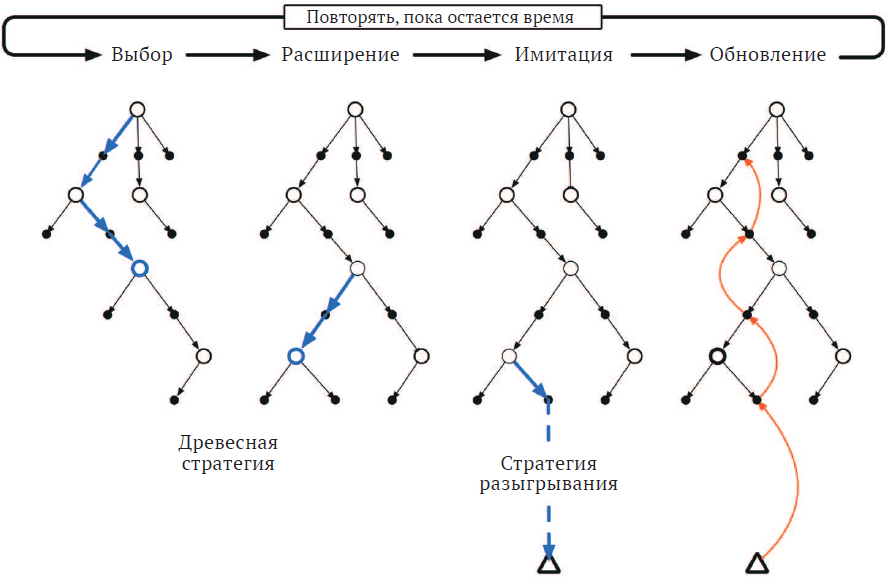

ПДМК **<font color='orange'>инкрементно расширяет это дерево</font>** – добавляет в него узлы, представляющие наиболее многообещающие состояния, основываясь на результатах имитированных траекторий. **<font color='orange'>Любая имитированная траектория будет проходить по этому дереву и завершаться в каком-то листовом узле</font>**. **<font color='orange'>Вне дерева и в листовых узлах</font>** для выбора действий используется **<font color='orange'>стратегия разыгрывания</font>**, но **<font color='orange'>для состояний во внутренних узлах</font>** дерева есть более приклекательная альтернатива. В этих состояниях у нас имеются оценки хотя бы некоторых действий, поэтому мы можем выбирать из них, применяя так называемую **<font color='orange'>древесную стратегию</font>**, сочетающую исследование и использование.

Т.о. ПДМК состоит из следующих этапов.

1.   **<font color='orange'>Выбор.</font>** Начав с корневого узла, древесная стратегия обходит дерево для выбора листового узла, основываясь на ценностях действий, которыми помечены ребра дерева.
2.   **<font color='orange'>Расширение.</font>** На некоторых итерациях (каких именно, зависит от реализации) дерево расширяется путем добавления одного или нескольких потомков выбранного листового узла, достижимых из выбранного узла с помощью действий, не требующих исследования.
3.   **<font color='orange'>Имитация.</font>** Из выбранного узла или одного из его вновь добавленных потомков (если таковые имеются) запускается имитация полного эпизода с действиями, выбираемыми стратегией разыгрывания. Результатом является имитация метода Монте-Карло с действиями, выбранными сначала древесной стратегией, а вне дерева – стратегией разыгрывания.
4.   **<font color='orange'>Обновление.</font>** Доход, сгенерированный в имитированном эпизоде, используется, чтобы обновить или инициализировать ценности действий, присоединенные к ребрам дерева, которое обходит древесная стратегия на этой итерации ПДМК. Ценности состояний и действий, посещенных согласно стратегии разыгрывания вне дерева, не сохраняются. На рисунке это иллюстрируется обновлением узла $(s,a)$, в котором началась стратегия разыгрывания, непосредственно из заключительного состояния имитированной траектории.

**<font color='orange'>ПДМК выполняет эти четыре шага каждый раз в течение заданного количества времени (или заданного количества шагов), начиная с корня дерева</font>**. Затем **<font color='orange'>в корневом узле выбирается действие согласно некоторому механизму</font>**, зависящему от накопленной в дереве статистики. Это и будет действие, выбранное методом ПДМК. После этого выполнняется **<font color='orange'>имитация некоторой траектории из этого узла</font>** пока не попадется конечное состояние или не кончится отведенное время (или еще какой-то вычислительный ресурс). Далее выполняется **<font color='orange'>обновление</font>** - в данном случае (табличный вариант) **<font color='orange'>таблицы $Q$</font>**. **<font color='orange'>После этого среда переходит в новое состояние, и ПДМК запускается опять</font>**.

Иногда он начинается с дерева, содержащего только корневой узел, который представляет новое состояние, но **<font color='orange'>чаще с дерева, содержащего всех потомков этого узла</font>**, оставшихся **<font color='orange'>от дерева, построенного при предыдущем выполнении ПДМК</font>**.


### Код для ПДМК

В данном случае в коде используется лабиринт из примера №3 прошлой методички (7(1)_Planning).

Для обучения и планирования используется Q-обучение, как и в прошлой методичке. В качестве стратегии выбора действия из корневого узла в этой версии ПДМК взята стратегия UCT (Upper Confidence Trees). Глубина построения траектории в имитации - n_step = $30$ шагов. А общее количество повторений - n_simulations = 40.

In [ ]:
# =====================================================================
# Среда
# =====================================================================
class ChangingMazeEnvironment:
    def __init__(self):
        self.width = 9
        self.height = 6
        self.start_state = (3, 0) # ИСПРАВЛЕНО: Старт перенесен в (3,0)
        self.terminal_state = (8, 5)
        self.state = self.start_state
        self.wall_close = [(1, 2), (2, 2), (3, 2), (4, 2), (5, 2), (6, 2), (7, 2), (8, 2)]  # Открыт длинный путь
        self.wall_open =  [(1, 2), (2, 2), (3, 2), (4, 2), (5, 2), (6, 2), (7, 2)] # Открыты оба пути
        self.actions = [(0,-1), (1,0), (0,1), (-1,0)]
        self.wall_clock = 3000
        self.term_reward = 100
        self.nonterm_reward = 0

    def get_walls(self, global_count):
        current_walls = self.wall_close if global_count < self.wall_clock else self.wall_open
        return current_walls

    def reset(self):
        self.state = self.start_state
        return self.state

    def step(self, action, global_count):
        current_walls = self.wall_close if global_count < self.wall_clock else self.wall_open
        x, y = self.state
        old_x, old_y = self.state

        if action == 0: y = max(0, y + self.actions[action][1])
        elif action == 1: x = min(9 - 1, x + self.actions[action][0])
        elif action == 2: y = min(6 - 1, y + self.actions[action][1])
        elif action == 3: x = max(0, x + self.actions[action][0])

        if (x, y) in current_walls:
            x, y = old_x, old_y

        self.state = (x, y)

        if self.state == self.terminal_state:
            return self.state, self.term_reward, True
        else:
            return self.state, self.nonterm_reward, False

    def sim_step(self, sim_state, sim_action, global_count):
        current_walls = self.wall_close if global_count < self.wall_clock else self.wall_open
        x, y = sim_state
        old_x, old_y = x, y

        if sim_action == 0: y = max(0, y + self.actions[sim_action][1])
        elif sim_action == 1: x = min(9 - 1, x + self.actions[sim_action][0])
        elif sim_action == 2: y = min(6 - 1, y + self.actions[sim_action][1])
        elif sim_action == 3: x = max(0, x + self.actions[sim_action][0])

        if (x, y) in current_walls:
            x, y = old_x, old_y

        sim_state = (x, y)

        if sim_state == self.terminal_state:
            return sim_state, self.term_reward, True
        else:
            return sim_state, self.nonterm_reward, False
# =====================================================================
# ПДМК
# =====================================================================
class MCTSNode:
    def __init__(self, state, parent=None, parent_action=None):
        self.state = state
        self.parent = parent
        self.parent_action = parent_action
        self.children = {}
        self.visits = 0
        self.total_reward = 0.0
        self.N_sa = np.zeros(4)
        self.W_sa = np.zeros(4)

    def is_fully_expanded(self):
        return len(self.children) == len(env.actions)

def mcts_plan_action(env, root_state, model, model_time, Q, n_simulations, alpha, gamma, global_count, c_param=2.0, terminal_state=(8,5)):
    root = MCTSNode(root_state)
    current_walls = env.get_walls(global_count)
    plus_kappa = 0.01
    n_step = 30

    for _ in range(n_simulations):
        node = root
        depth = 0

        # Выбор (SELECTION)
        while node.state != env.terminal_state and node.is_fully_expanded():
            best_action = None
            best_ucb = -float('inf')
            x, y = node.state

            # UCT (Upper Confidence Trees) - стратегия выбора действия с помощью верхних доверительных границ
            for a in range(len(env.actions)):
                if node.N_sa[a] == 0:
                    ucb = float('inf')
                else:
                    # Составляющие UCB1 (Upper Confidence Bound 1, Верхняя доверительная граница 1)
                    exploitation = node.W_sa[a] / node.N_sa[a]
                    exploration = c_param * math.sqrt(math.log(node.visits + 1) / node.N_sa[a])
                    # Добавляем бонус из Dyna-Q+ для проверки изменений
                    last_seen = model_time[x, y, a]
                    time_bonus = plus_kappa * math.sqrt(global_count - last_seen)
                    # Доказательство применения UCB1 в деревьях ПДМК - https://link.springer.com/chapter/10.1007/11871842_29
                    # Общий разбор различных модификаций и составляющих за 2012 год https://sci-hub.usualwant.com/10.1109/tciaig.2012.2186810
                    ucb = exploitation + exploration + time_bonus

                if ucb > best_ucb:
                    best_ucb = ucb
                    best_action = a

            if best_action is None or best_action not in node.children:
                break

            node = node.children[best_action]
            depth += 1

        # Расширение (EXPANSION)
        if node.state != env.terminal_state and not node.is_fully_expanded():
            unvisited_actions = [a for a in range(len(env.actions)) if a not in node.children]
            chosen_action = np.random.choice(unvisited_actions)

            sx, sy = node.state
            model_prediction = model[sx, sy, chosen_action]
            if model_prediction is not None:
                r, next_state = model_prediction
            else:
                next_state, r, _ = env.sim_step(node.state, chosen_action, global_count)

            child_node = MCTSNode(next_state, parent=node, parent_action=chosen_action)
            node.children[chosen_action] = child_node
            node = child_node
            depth += 1

        # Имитация (симуляция) (SIMULATION)
        sim_state = node.state
        steps_taken = 0
        found_target = False

        for _ in range(n_step):
            if sim_state == env.terminal_state:
                found_target = True
                break

            sim_act = np.random.randint(0, len(env.actions))
            next_state, _, _ = env.sim_step(sim_state, sim_act, global_count)

            sim_state = next_state
            steps_taken += 1
            if sim_state == env.terminal_state:
                found_target = True
                break

        total_steps = depth + steps_taken
        x, y = sim_state
        if found_target:
            discounted_final_reward = env.term_reward * (gamma ** total_steps)
        else:
            discounted_final_reward = np.max(Q[x, y]) * (gamma ** total_steps)

        # Обновление (BACKPROPAGATION)
        curr_node = node
        while curr_node is not None:
            curr_node.visits += 1
            curr_node.total_reward += discounted_final_reward

            if curr_node.parent is not None:
                px, py = curr_node.parent.state
                act = curr_node.parent_action
                cx, cy = curr_node.state

                step_reward = env.term_reward if curr_node.state == env.terminal_state else env.nonterm_reward
                curr_node.parent.N_sa[act] += 1
                curr_node.parent.W_sa[act] += discounted_final_reward

                max_next_Q = 0 if curr_node.state == env.terminal_state else np.max(Q[cx, cy])
                Q[px, py, act] += alpha * (step_reward + gamma * max_next_Q - Q[px, py, act])

            curr_node = curr_node.parent

    return np.argmax(root.N_sa)

def get_optimal_path(env, Q, global_count):
    state = env.start_state
    path = [state]
    steps = 0
    while state != env.terminal_state and steps < 40:
        x, y = state
        action = np.argmax(Q[x, y])
        state, _, _ = env.sim_step(state, action, global_count)
        if state == path[-1]: break
        path.append(state)
        steps += 1
    print(path)
    return path

# =====================================================================
# Карта
# =====================================================================
def draw_maze(env, path, global_count):
    grid = np.full((env.height, env.width), ".")
    current_walls = env.get_walls(global_count)
    for wx, wy in current_walls:
        grid[wy, wx] = "█"
    for x, y in path:
        grid[y, x] = "•"
    grid[env.start_state[1], env.start_state[0]] = "S"
    grid[env.terminal_state[1], env.terminal_state[0]] = "F"

    print("\n".join([" ".join(row) for row in grid]))
    print()

# =====================================================================
# Базовый цикл
# =====================================================================
def run_dynamic_maze():
    env = ChangingMazeEnvironment()
    Q = np.zeros((env.width, env.height, len(env.actions)))
    Model = np.empty((env.width, env.height, len(env.actions)), dtype=object)
    Model.fill(None)
    Model_Time = np.zeros((env.width, env.height, len(env.actions)))

    alpha = 0.3
    gamma = 0.90
    epsilon = 0.15
    n_simulations = 40
    global_count = 1
    print(f"Старт в {env.start_state}, финиш {env.terminal_state} на 6000 шагов...")

    while global_count <= 6000:
        state = env.reset()
        is_terminal = False

        while not is_terminal and global_count <= 6000:
            if np.random.sample() < epsilon:
                action = np.random.randint(0, len(env.actions))
            else:
                action = mcts_plan_action(env, state, Model, Model_Time, Q, n_simulations, alpha, gamma, global_count)

            next_state, reward, is_terminal = env.step(action, global_count)

            x, y = state
            nx, ny = next_state

            max_Q = 0 if is_terminal else np.max(Q[nx, ny])
            Q[x, y, action] += alpha * (reward + gamma * max_Q - Q[x, y, action])

            Model[x, y, action] = (reward, next_state)
            Model_Time[x, y, action] = global_count

            # Вывод карты каждые 1500 шагов для демонстрации перестройки пути
            if global_count % 1500 == 0:
                current_walls = env.wall_close if global_count < env.wall_clock else env.wall_open
                path = get_optimal_path(env, Q, global_count)
                status = "ЗАКРЫТ" if global_count < env.wall_clock else "ОТКРЫТ"
                print(f"\n[Шаг {global_count}] Короткий путь {status}. Маршрут: {len(path)-1} шагов.")
                draw_maze(env, path, global_count)

            state = next_state
            global_count += 1

run_dynamic_maze()

Старт в (3, 0), финиш (8, 5) на 6000 шагов...
[(3, 0), (2, 0), (1, 0), (1, 1), (0, 1), (0, 2), (0, 3), (1, 3), (2, 3), (3, 3), (4, 3), (5, 3), (6, 3), (7, 3), (7, 4), (8, 4), (8, 5)]

[Шаг 1500] Короткий путь ЗАКРЫТ. Маршрут: 16 шагов.
. • • S . . . . .
• • . . . . . . .
• █ █ █ █ █ █ █ █
• • • • • • • • .
. . . . . . . • •
. . . . . . . . F

[(3, 0), (3, 1), (2, 1), (1, 1), (0, 1), (0, 2), (0, 3), (1, 3), (2, 3), (3, 3), (4, 3), (5, 3), (6, 3), (7, 3), (8, 3), (8, 4), (8, 5)]

[Шаг 3000] Короткий путь ОТКРЫТ. Маршрут: 16 шагов.
. . . S . . . . .
• • • • . . . . .
• █ █ █ █ █ █ █ .
• • • • • • • • •
. . . . . . . . •
. . . . . . . . F

[(3, 0), (4, 0), (5, 0), (6, 0), (7, 0), (8, 0), (8, 1), (8, 2), (8, 3), (8, 4), (8, 5)]

[Шаг 4500] Короткий путь ОТКРЫТ. Маршрут: 10 шагов.
. . . S • • • • •
. . . . . . . . •
. █ █ █ █ █ █ █ •
. . . . . . . . •
. . . . . . . . •
. . . . . . . . F

[(3, 0), (4, 0), (5, 0), (6, 0), (7, 0), (8, 0), (8, 1), (8, 2), (8, 3), (8, 4), (8, 5)]

[Шаг 6000] Коро

#### Обсуждение 1


1. Выберите среду из gymnasium (например, Frozen Lake или Taxi) и адаптируйте для нее ПДМК. Сравните результаты простого обучения (без планирования) и обучения с планированием (время обучения, средняя награда, оптимальная политика), а также сравните время обучения от глубины построения траектории в ПДМК (в базовом коде n_step = $30$) и количества повторений (в базовом коде n_simulations = 40). Можно брать среду из проекта за прошлый семестр.

#### Подсказки 1

1.   Берем опорный код ПДМК с лабиринтом, меняем под свою среду или пишем свой вариант ПДМК и строим графики.

# Улучшение предсказаний для всех посещенных состояний

Еще одно интересное улучшение началось с попытки выделить оптимальное $n$ для $n$-шаговых TD-методов.

Фактически, это **<font color='orange'>способ комбинирования TD и МК без необходимости отслеживать</font>** (помнить и считать) **<font color='orange'>n-шаговые переходы на каждом этапе</font>**. В качестве цели в таких методах используется **<font color='orange'>взвешенное сочетание n-шаговых целей</font>**.

Когда TD-методы дополняются следами применимости, образуется новое семейство методов, охватывающее широкий спектр подходов, на одном конце которого ($λ = 1$) находятся методы МК, а на другом ($λ = 0$) – одношаговые TD-методы. Между ними располагаются промежуточные методы, которые также часто оказываются лучше, чем крайние варианты. Иногда это называют **<font color='orange'>обобщенным бутстрэппингом</font>**.

>Когда $λ = 1$, единственный активный вес у МК, если $λ = 0$, то активен только одношаговый TD($0$), а значения посередине сочетают в себе все $n$-шаговые предсказания.

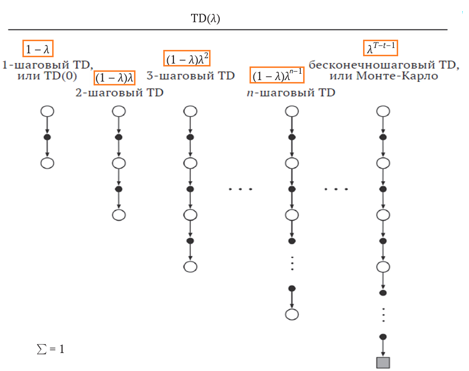

Также появляется способ реализации методов МК в онлайновом режиме и для непрерывных задач без эпизодов. Помощь в этом оказали **<font color='orange'>следы значимости</font>**. Или, как их еще называют: следы правомочности, следы применимости, следы приемлемости, следы соответствия, следы активности, «элиджибилити трейсы», «трейсы», «следы» или, наконец, **<font color='orange'>eligibility traces</font>**.

Главное вычислительное преимущество следов применимости над $n$-шаговыми методами заключается в том, что **<font color='orange'>нужно хранить только один вектор следа</font>**, а не $n$ последних векторов признаков. Кроме того, **<font color='orange'>обучение происходит непрерывно и равномерно во времени</font>**, а не откладывается до конца эпизода. Дополнительно обучение может иметь место и влиять на поведение сразу после обнаружения состояния, без задержки на $n$ шагов.

Многие алгоритмы наиболее естественно формулируются и интерпретируются как обновление ценности состояния, исходя из событий, которые **<font color='orange'>последовали за этим состоянием</font>** на протяжении нескольких временных шагов. Например, в методах МК состояние обновляется на основе всех будущих вознаграждений, а в $n$-шаговых TD-методах – на основе следующих n вознаграждений и состояния, отстоящего на $n$ шагов в будущем.

> На рисунке ниже все стандартно - как мы делали раньше, от текущего состояния смотрим в даль и ориентируемся на дисконтируемую награду.

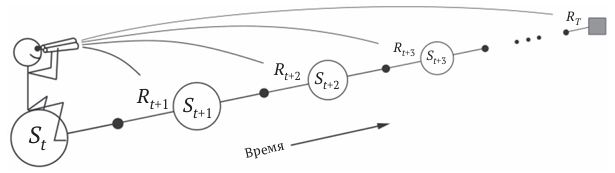

Такие формулировки, основанные на заглядывании вперед из обновляемого состояния называются **<font color='orange'>прямым представлением</font>** (forward view). Прямые представления всегда несколько сложнее реализовать, потому что **<font color='orange'>обновление зависит от того, что случится позднее</font>**, а в момент обновления неизвестно.

Но часто можно достичь такого же или почти такого же обновления с помощью алгоритма, в котором используется **<font color='orange'>текущая TD-ошибка и производится оглядывание назад на недавно посещенные состояния с применением следа значимости</font>**. Эти альтернативные способы анализа состояния и реализации алгоритмов обучения называются **<font color='orange'>обратными представлениями</font>** (backward view).

>На рисунке ниже $δ_t$ - это TD-ошибка, а $z_t$ - след значимости, так как каждое обновление зависит от текущей TD-ошибки в сочетании с текущими следами значимости прошлых событий.

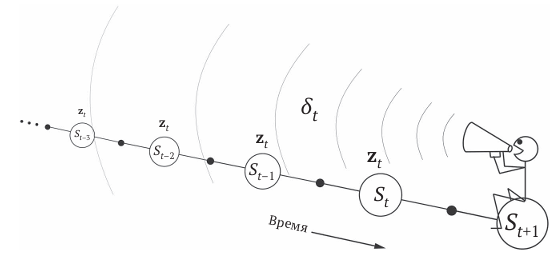

Обратные представления, преобразования между прямыми и обратными представлениями и их эквивалентность – все это появилось вместе с обучением на основе временных различий, но основное развитие получило после 2014 года.

## TD(λ) прямого представления
> В TD(λ) прямого представления сам механизм следов значимости не используется, но именно он дает базу с формулами, позволяя проследить изменения и понять дальнейшие преобразования.

В текущем курсе мы посмотрим только на **<font color='orange'>эпизодический вариант с on-policy</font>**. Перейдем к формулам и начнем с **<font color='orange'>дохода</font>**. Здесь $G^{λ}_{t:T}$ это тоже само, что $G^{λ}_t$, $G_{t:T}$ это тоже само, что $G_t$.

(1)
$$G^{λ}_{t:T} = (1-λ) ∑^{T-t-1}_{n=1} λ^{n-1} G_{t:t+n} + λ^{T-t–1}G_{t:T}.$$

Здесь $(1-λ) ∑^{T-t-1}_{n=1} λ^{n-1} G_{t:t+n}$ - **<font color='orange'>суммарный взвешенный доход шагов от $1$ до $T$</font>**, а $λ^{T-t–1}G_{t:T}$ - **<font color='orange'>окончательный взвешенный доход</font>**.

Таким образом, по формуле (1) мы последовательно **<font color='orange'>вычисляем $n$-шаговые доходы</font>** (начиная от одношагового, двухшагового и далее до $n$ или конца эпизода) и **<font color='orange'>взвешиваем их</font>**. Один из минусов такого подхода в том, что, как и в МК, вначале **<font color='orange'>нужно сгенерировать весь эпизод</font>**. Это есть и в $n$-шаговых TD, просто отставание меньше. Это чем-то похоже на догонялки с отставанием в $n$ шагов.

Часто это формулу можно увидеть без вынесения $λ^{T-t–1}G_{t:T}$, так как этот член отделяется от остновной суммы при достижении заключительного состояния (после достижения $T$ все последующие n-шаговые доходы берутся равными традиционному доходу $G_t$ или $G_{t:T}$). Поэтому можно встретить более короткий вариант формулы: $G^{λ}_{t} = (1-λ) ∑^{∞}_{n=1} λ^{n-1} G_{t:t+n}$.

**<font color='orange'>Общая формула обучения остается, как в $n$-шаговом TD</font>** с заменой дохода на $G^{λ}_t$.

Плюсом данного метода является снижение дисперсии, хотя смещение остается.

## TD(λ) прямого представления

**<font color='orange'>TD(λ) обратного представления</font>** (именно его чаще всего имеют в виду под названием TD(λ)) позволяет балансировать между смещением и дисперсией и **<font color='orange'>применять обновления на каждом временном шаге</font>**, т.е. метод работает как одношаговый TD, и за счет этого может использоваться в **<font color='orange'>онлайн обучении</font>**. Онлайн обучение подразумевают обновление функции ценности на каждом шаге, что **<font color='orange'>влияет и на сам процесс предсказания</font>**.

Такое преимущество дают **<font color='orange'>следы значимости</font>**. Фактически, это **<font color='orange'>вектор памяти</font>**, который хранит историю недавно посещенных состояний. Суть в том, чтобы **<font color='orange'>связать награду с состояниями, которые находятся к получению этой награды ближе</font>**, так как они с большей вероятностью на это повлияли. **<font color='orange'>Это же касаестся и ошибки оценки</font>**.

Давайте рассмотрим поближе, что происходит при применении следов значимости при работе в среде с четырьмя состояниями: $S_0$, $S_1$, $S_2$, $S_3$. В течение рассматриваемого эпизода агент посетил состояния в следующем порядке: $S_1$, $S_2$, $S_1$, $S_0$, $S_3$, $S_3$, $S_3$, $S_0$, $S_3$. Тогда значения коэффициента следов значимости будет меняться для состояний следующим образом:

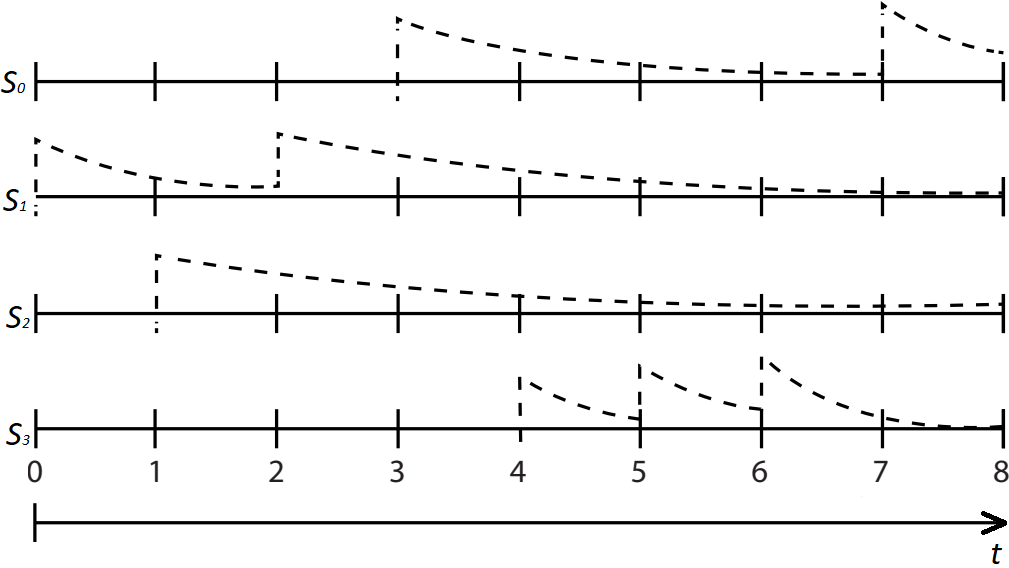

Например, рассматривая состояние $S_0$ можно заметить, что **<font color='orange'>коэффициент следов значимости повышается на шагах, когда состояние посещалось</font>** (3 и 7 временные шаги). Причем после шага 3 и 7 следует **<font color='orange'>затухание</font>**. На временном шаге 4 видно, что наибольший вклад будет у состояния $S_3$, затем $S_0$, потом $S_1$ и наименьший у $S_2$.

В процессе работы **<font color='orange'>на каждом временном шаге</font>** вычисляется **<font color='orange'>обновление функции ценности для всех состояний</font>** и умножается на **<font color='orange'>вектор следов значимости</font>**, таким образом обновляются не все состояния, а только определенные. **<font color='orange'>Затухает вектор на величину $λ$ и $γ$</font>**.

Перейдем к формулам. Чтобы было проще, разберем происходящее **<font color='orange'>по шагам</font>**. Для начала нам потребуется **<font color='orange'>формула погрешности</font>** (методичка 5):

(2)
$$δ_t = R_{t+1} + γV(S_{t+1}) - V(S_t)$$

и сам **<font color='orange'>вектор следов значимости $E$</font>**.

Тогда:
*  в начале каждого эпизода **<font color='orange'>вектор следов значимости</font>** нужно **<font color='orange'>обнулить $E=0$</font>**;
*  **<font color='orange'>провзаимодействовать со средой</font>**, получив к имеющимся **<font color='orange'>$S_t$, $A_t$</font>** еще **<font color='orange'>$R_{t+1}$, $S_{t+1}$</font>**;
*  далее **<font color='orange'>увеличиваем состояние вектора следов</font>** для состояния **<font color='orange'>$S_t$</font>** на единицу **<font color='orange'>$E(S_t) = 1$</font>**;
*  вычисляем **<font color='orange'>погрешность $δ_t$</font>**;
*  обновляем **<font color='orange'>функцию ценности $V$</font>**, только теперь не конкретного состояния $V(S_t)$, а **<font color='orange'>всю</font>** (по всем состояниям) **<font color='orange'>$V = V + α*δ_t*E$</font>**;
*  затем **<font color='orange'>уменьшаем следы значимости</font>** (затухание) **<font color='orange'>$E=γλE$</font>**.

**<font color='orange'>При $λ=0$</font>** метод превращается в обычный **<font color='orange'>TD(0)</font>** (поэтому его так и обозначают), а **<font color='orange'>при $λ=1$</font>** превращается в **<font color='orange'>МК с накапливающимися обновлениями</font>**.

Также существуют такие же **<font color='orange'>модификации для SARSA и Q-learning</font>** (SARSA(λ) с двумя вариантами следов значимости, Q(λ) по Уоткинсу, Q(λ) Пенга, Tree Backup (TB(λ))).

#### Обсуждение 2


1. На примере случайного блуждания с МПВ с девятнадцатью состояниями сравните эффективность работы TD(λ) и TD(λ) прямого представления при разных $λ$.

#### Подсказки 2

1.   Возьмите код обсуждения №2 из методички с бутстреппингом (6_Bootstrapping) для 19 состояний и модифицируйте для сравнения TD(λ) и TD(λ) прямого представления в виде функции от $α$ для значений $λ = \{0, 0.2, 0.4, 0.8, 0.9, 0.95, 0.975, 0.99, 1\}$ вместо $n$.

Теперь давайте немного подведем итоги с табличными методами и разберемся, почему большие среды не подходят для табличных методов и как вообще тогда с ними жить.

# Подведение итогов по табличным методам

Все рассмотренные ранее методы характеризуются **<font color='orange'>тремя общими ключевыми идеями</font>**. Во-первых, все они **<font color='orange'>оценивают функции ценности</font>**. Во-вторых, принцип действия каждого основан на **<font color='orange'>обновлении ценностей вдоль реальных или возможных траекторий изменения состояний</font>**. В-третьих, все они используют **<font color='orange'>подход на основе обобщенной итерации по стратегиям</font>** (ОИС), т.е. хранят приближенную функцию ценности и приближенную стратегию и постоянно пытаются улучшить одну на основе другой.

Согласно Richard S. Sutton и Andrew G. Barto, функции ценности, обновление ценностей и ОИС - **<font color='orange'>главные организующие принципы, свойственные любой модели интеллекта</font>**, искусственного или естественного. А две наиболее важные оси, вдоль которых располагаются различные методы, это **<font color='orange'>ширина и глубина обновления</font>**.

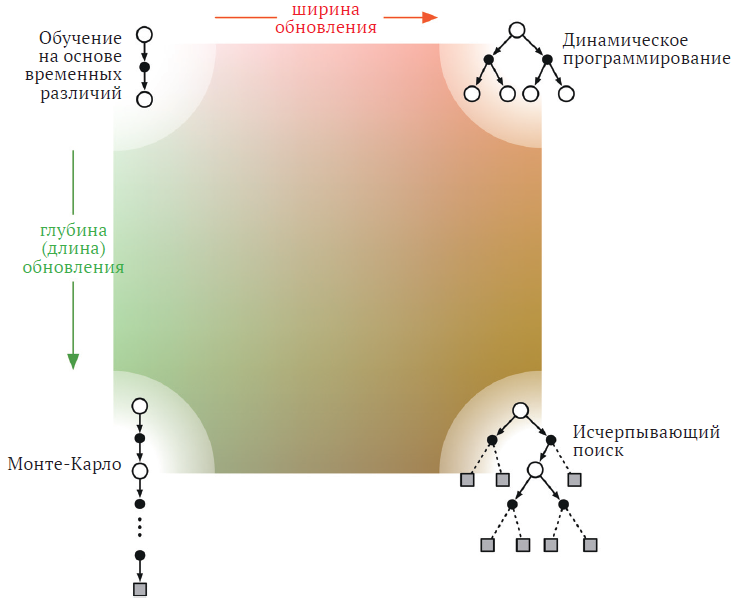


Вдоль **<font color='orange'>горизонтальной оси</font>** располагаются **<font color='orange'>выборочные обновления</font>** (основанные на выборочной траектории) и **<font color='orange'>полные обновления</font>** (основанные на распределении возможных траекторий). Для полных обновлений необходима модель распределения, а для выборочных – только модель выборки, хотя их можно производить на основе реального опыта, вообще без модели (еще одна ось изменения). **<font color='orange'>Вертикальная ось</font>** соответствует глубине обновлений, т.е. **<font color='orange'>степени бутстрэппинга</font>**. В **<font color='orange'>трех углах</font>** пространства из четырех находятся основные методы оценивания ценности: **<font color='orange'>ДП, TD и МК</font>**. Вдоль левого края пространства располагаются методы выборочного обновления – от одношаговых TD-обновлений до обновлений Монте-Карло с полным доходом. В **<font color='orange'>правом нижнем углу</font>** расположен случай максимально глубокого полного обновления, продолжающегося до заключительного состояния. Это случай **<font color='orange'>исчерпывающего поиска</font>**. К промежуточным методам вдоль этой оси относятся эвристический поиск и связанные с ним методы. Существуют также методы, сочетающие полное и выборочное обновления, а еще методы, сочетающие модель выборки и модель распределения в одном обновлении. Залитая внутренняя часть квадрата представляет пространство всех таких промежуточных методов.

**<font color='orange'>Третья ось</font>** – это бинарное **<font color='orange'>различие между методами с единой и разделенной стратегиями</font>**. Ее можно представить как перпендикуляр к плоскости, изображенной на рисунке.

Помимо этих трех осей, можно выделить **<font color='orange'>еще несколько</font>**:

*   **<font color='orange'>Определение дохода</font>** (эпизодическая задача или нет).
*   **<font color='orange'>Ценности действий, ценности состояний и ценности послесостояний</font>** (что оценивается).
*   **<font color='orange'>Стратегия выбора действия</font>** (баланс исследования и использования).
*   **<font color='orange'>Синхронно или асинхронно</font>** (обновляются сразу все состояния или последовательно в каком-то порядке).
*   **<font color='orange'>Реальный или имитированный опыт</font>** (на каком опыте основано обновление; или на обоих сразу).
*   **<font color='orange'>Место обновления</font>** (какие именно состояния или состояния-действия обновляются).
*   **<font color='orange'>Время обновления</font>** (в момент выбора действия или только после).
*   **<font color='orange'>Память для обновлений</font>** (сколько и как храним обновленные ценности).
*   **<font color='orange'>И т.д.</font>**

Еще одна ось, которую мы здесь не рассматривали - **<font color='orange'>аппроксимация функций</font>**. Это важнейшая часть при переходе к **<font color='orange'>глубокому обучению с подкреплением</font>**. Ее можно рассматривать как совершенно независимый спектр возможностей, на одном конце которого находятся табличные методы, а далее следуют агрегирование состояний, разнообразные линейные и, наконец, нелинейные методы (deep reinforcement learning).



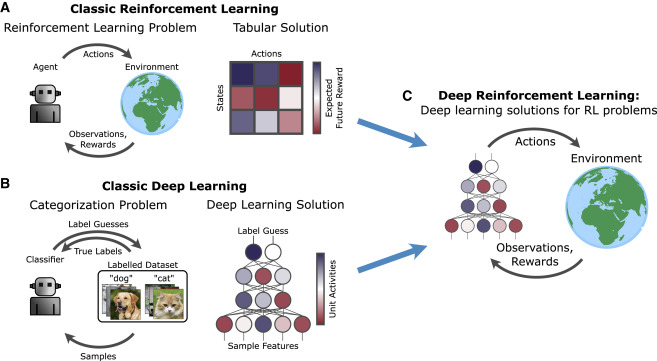

# Приближенные методы решения

Для начала взглянем на **<font color='orange'>виды обратной связи</font>**, которые мы успели посмотреть в течение наших лекций, и какие нам потребуются далее.

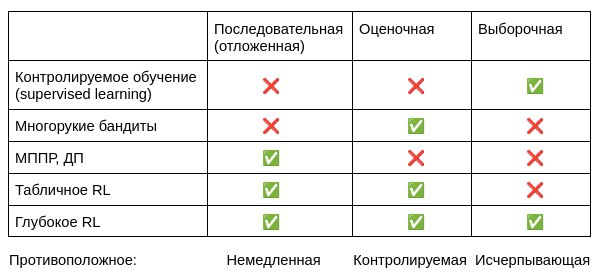

Итак, на курсе Большие данные Вы проходили в частности так называемое **<font color='orange'>обучение с учителем или контролируемое обучение</font>**, когда мы обучаем **<font color='orange'>по выборке</font>**, содержащей правильный ответ. Таким образом, отложенная связь отсутствует, т.к. мы сразу сообщаем, что правильно, и оценочная, т.к. мы сообщаем правильный ответ и заставляем под него выравниваться.

В начале нашего курса мы смотрели многоруких бандитов. В их случае у нас есть **<font color='orange'>оценочная связь</font>**, так как начиная играть в среде агент не знает правильного ответа и распределения вероятностей в среде. Но все эксперименты на 1 шаг в эпизоде, поэтому нет отложенной связи и выборочной.

В ДП у нас присутствует **<font color='orange'>анализ на несколько шагов</font>**, т.е. мы имеем возможность отслеживать последовательность принимаемых решений. Но мы перебираем все возможные варианты и знаем точное распределение вероятностей в среде.

В табличном RL, куда входят МК, TD и n-шаговые варианты, мы не только смотрели на **<font color='orange'>последовательности решений</font>**, но и **<font color='orange'>оценивали их относительно последствий</font>**. Однако, старались рассмотреть все возможные комбинации состояний $s$ и действий $a$.

**<font color='orange'>В глубоком RL</font>**, как и в целом в приближенных методах, нам нужно будет отказаться и от варианта рассмотреть все состояния и действия.

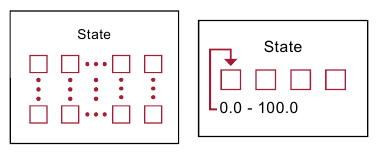


Это связано с тем, что в больших задачах не только **<font color='orange'>состояния и/или действия могут быть многомерными</font>** (например, один кадр в игре Atari состоит из $210*160*3 = 100800$ пикселей по которым агент будет принимать решение), но и **<font color='orange'>непрерывными</font>**, т.е. принимать бесконечное количество значений (например, ширина в см может обладать бесконечно высокой точностью: 2.1, 2.12, 2.123 и т.д; а в табличном варианте нужно учитывать все эти варианты). Тогда **<font color='orange'>таблица оценок становится бесконечной</font>**, а наши табличные методы **<font color='orange'>перестают сходиться к оптимальной стратегии</font>** за счет условий эксплуатации.

Тогда нам на помощь приходит **<font color='orange'>аппроксимация функций</font>**. Давайте посмотрим, как будет выглядеть некоторая функция ценности состояния с аппроксимацией и без.

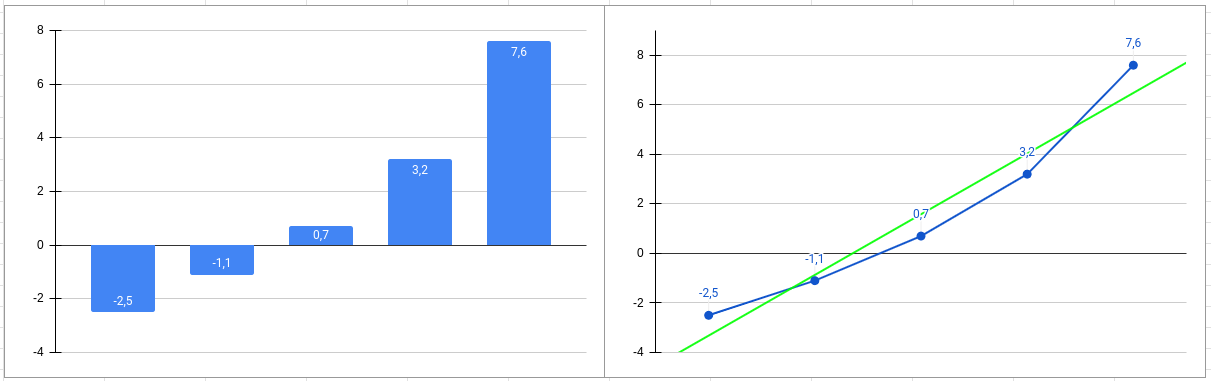

**<font color='orange'>Без аппроксимации все значения независимы</font>**, а **<font color='orange'>с аппроксимацией мы можем также предсказывать значения между известными нам значениями функции ценности</font>**. Более того, если у нас поменяется какое-то из значений, например вместо 7.6 станет 5.5, то поменяется не только оценка этой оценки, но других. На рисунках выбрана линейная зависимость, но она может быть и другой. Например, нейронные сети позволяют находить более сложные связи.

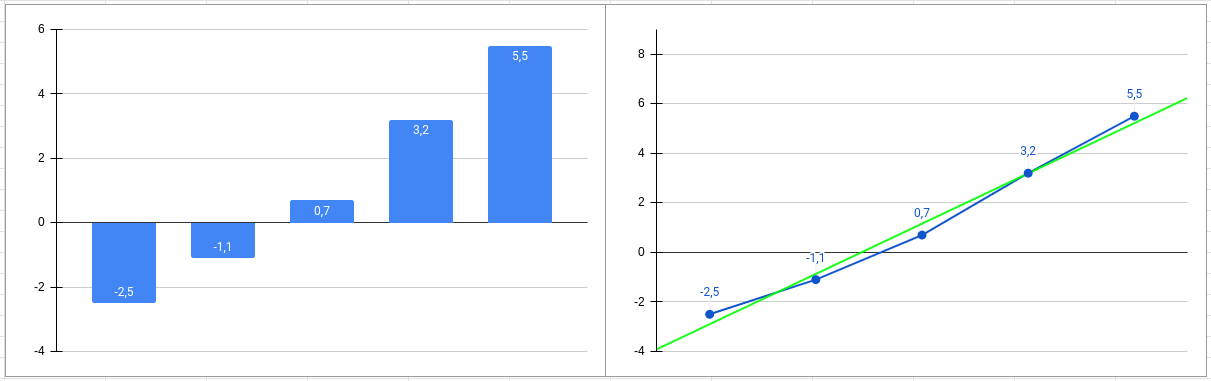

У функций ценности часто есть **<font color='orange'>внутренние связи</font>**, которые агент может исследовать и использовать. А **<font color='orange'>аппроксиматоры функций способны их обнаружить</font>**.

Рассмотрение **<font color='orange'>каждого обновления как традиционного обучающего примера</font>** (как в машинном обучении в методах обучения с учителем) дает нам возможность **<font color='orange'>применять</font>** любой из широкого спектра существующих **<font color='orange'>методов аппроксимации функций для предсказания ценности</font>**. В принципе, можно использовать любой **<font color='orange'>метод обучения с учителем</font>** на примерах, в т.ч. нейронные сети, решающие деревья и различные варианты многомерной регрессии. Однако, **<font color='orange'>не все методы аппроксимации функции одинаково хорошо подходят</font>** для использования в обучении с подкреплением. Наиболее развитые нейросетевые модели и статистические методы предполагают наличие **<font color='orange'>статического обучающего набора</font>**, по которому производится несколько проходов. Но в обучении с подкреплением важно, чтобы **<font color='orange'>обучение</font>** проходило **<font color='orange'>в онлайновом режиме</font>**, в процессе взаимодействия агента с окружающей средой или ее моделью. Для этого необходимы **<font color='orange'>методы, способные эффективно обучаться на основе постепенно поступающих данных</font>**. Кроме того, для обучения с подкреплением, вообще говоря, требуются **<font color='orange'>методы аппроксимации функций, способные работать с нестационарной</font>** (изменяющейся во времени) **<font color='orange'>целевой функцией</font>**. Например, в методах управления, основанных на ОИС (обобщенная итерация по стратегиям), мы часто стремимся **<font color='orange'>обучить $q_π$</font>**, в то время как сама **<font color='orange'>стратегия $π$ изменяется</font>**. Даже если стратегия остается неизменной, выходные значения в обучающих примерах будут **<font color='orange'>нестационарными</font>**, если генерируются методами бутстрэппинга (ДП и TD-обучение). **<font color='orange'>Методы, которые не могут работать в условиях такой нестационарности, плохо подходят для обучения с подкреплением</font>**.


Теперь перейдем к целевой функции для предсказания. **<font color='orange'>В табличном случае непрерывная мера качества предсказания была не нужна</font>**, поскольку обученная функция ценности могла **<font color='orange'>в точности совпасть с истинной</font>**. Кроме того, обученные ценности каждого состояния были разделены – **<font color='orange'>обновление одного состояния не влияло на другое</font>**. Но при настоящей аппроксимации обновление одного состояния сказывается на многих других, и **<font color='orange'>невозможно сделать так, чтобы ценности всех состояний были правильны</font>**. По предположению, **<font color='orange'>состояний гораздо больше</font>**, чем весов аппроксимирующей функции, поэтому если **<font color='orange'>оценка для одного состояния оказывается точнее</font>**, то **<font color='orange'>оценки других неизбежно становятся менее точными</font>**. Поэтому мы должны определить, **<font color='orange'>какие состояния для нас более важны</font>**. Для этого вводится **<font color='orange'>математический критерий качества оценки ценности</font>** (какую ошибку хотим минимизировать), а затем на его основе мы **<font color='orange'>конструируем функцию потерь</font>** (loss функцию). Т.е. нужна разница между приближенной ценностью $\bar{v}(s, w)$ и истинной ценностью $v_π(s)$, а, например, за основу можем взять среднеквадратичную ошибку по всем состояниям. Таким образом, мы стараемся **<font color='orange'>найти глобальный или хотя бы локальный оптимум</font>**, в котором веса функции аппроксимации $w$ дают **<font color='orange'>наименьшую ошибку</font>**. И чаще всего в таких крупных методах мы удовлетворяемся именно **<font color='orange'>локальным оптимумом</font>**. И вот тут и кроется **<font color='orange'>проблема</font>**, потому что при некоторых условиях методы могут не только не сходится к некоторому оптимому и не приближаться к нему на желаемое расстояние, но и **<font color='orange'>могут вообще расходиться</font>**.

В целом, у нас есть варианты, какую взять аппроксимирующую функцию. Ее сложность зависит от сложности задачи - не стоит везде и сразу пытаться применить нейросети. Давайте рассмотрим некоторые из них, но для начала нам потребуется ввести **<font color='orange'>подходящий метод обучения для аппроксимации функций</font>**.

## Стохастические градиентные и полуградиентные методы

Одни из методов обучения для аппроксимации функций в задаче предсказания ценности это **<font color='orange'>методы, основанные на стохастическом градиентном спуске</font>** (СГС). Именно их мы возьмем за базу, чтобы кратко посмотреть, как происходит обучение. Среди всех методов аппроксимации функций СГС-методы относятся к числу **<font color='orange'>наиболее широко используемых</font>** и особенно хорошо **<font color='orange'>подходят для онлайнового обучения с подкреплением</font>**. Помимо СГС-методов есть еще аналитические, методы наименьших квадратов, безградиентные методы, градиентные методы второго порядка и другие.

В методах градиентного спуска **<font color='orange'>вектор весов</font>** является вектором-столбцом с фиксированным числом вещественных элементов, $w = (w_1, w_2, …)$, а **<font color='orange'>приближенная функция ценности</font>** $\bar{v}(s, w)$ является дифференцируемой функцией от $w$ для всех $s∈𝒮$. Мы будем **<font color='orange'>обновлять $w$ на каждом из последовательности дискретных временных шагов</font>** $t = 0, 1, 2, 3, …$, поэтому понадобится обозначение **<font color='orange'>$w_t$</font>** для вектора весов на каждом шаге. Обопремся для обучения, например, на **<font color='orange'>МК и ожидаемый доход $G_t$</font>**. Тогда, на каждом шаге (последовательном или из выборки) будем корректировать веса по формуле:

(3)
$$w_{t+1} = w_t + α[G_t - \bar{v}(S_t, w_t)]∇\bar{v}(S_t, w_t),$$

где $∇\bar{v}(S_t, w_t)$ - обозначает вектор-столбец **<font color='orange'>частных производных по элементам вектора $w_t$</font>**. Этот вектор частных производных является **<font color='orange'>градиентом</font>**. И СГС методы называются так, потому что **<font color='orange'>полный шаг в $w_t$ пропорционален антриградиенту квадратичной ошибки</font>**, а **<font color='orange'>обновление применяется только к одному шагу</font>** или примеру (который может выбираться случайным образом).

При использовании бутстреппинга, применить методы градиентного спуска в чистом виде не получится, так как хотя они учитывают влияние изменения
вектора весов $w_t$ на оценку, но **<font color='orange'>игнорируют его влияние на цель</font>**. Нужно использовать **<font color='orange'>полуградиентные методы</font>**. Однако, нужно учитывать, что у них уже **<font color='orange'>не такая высокая гарантия сходимости</font>**.

Например, при **<font color='orange'>TD(0)</font>** обновление весов будет происходить следующим образом:

(4)
$$w_{t+1} = w_t + α[R_{t+1} + γ\bar{v}(S_{t+1}, w_t) - \bar{v}(S_t, w_t)]∇\bar{v}(S_t, w_t).$$

Кроме этого, дополнительно можно использовать еще один инструмент - **<font color='orange'>агрегирование состояний</font>**. Агрегирование состояний – простая форма обобщения аппроксимации функций, в которой **<font color='orange'>состояния объединяются в группы с одной оценкой ценности</font>** (одним элементом вектора весов w) для каждой группы. Ценность состояния оценивается как элемент, соответствующий ее группе; при обновлении состояния изменяется только этот элемент. Агрегирование состояний – частный случай алгоритма СГС, в котором градиент $∇\bar{v}(S_t, w_t)$ равен 1 для элемента, соответствующего группе состояния $S_t$, и 0 для всех остальных элементов.

### Какие есть варианты аппроксимации

#### Линейные методы
> Используют СГС, но за счет **<font color='orange'>агрегирования (кодирования) состояний</font>** имеют свои преимущества. Именно **<font color='orange'>грамотное кодирование состояний</font>** превращает простую линейную модель в **<font color='orange'>мощный инструмент, способный конкурировать с нейросетями в классических задачах</font>**.

В этом случае говорят, что **<font color='orange'>приближенная функция ценности линейно зависит от весов</font>**, или просто линейна. Причем **<font color='orange'>состояниям $s$ соответствует вектор признаков</font>** $x(s) = · (x_1(s), x_2(s), …$, с таким же числом $d$ элементов, как у вектора $w$.

Тогда $\bar{v}(s, w) = ∑_{i=1}^dw_ix_i(s)$. Для линейных методов **<font color='orange'>признаки являются базисными функциями</font>**, потому что образуют **<font color='orange'>линейный базис множества приближенных функций</font>**. Конструирование $d$-мерных векторов признаков для представления состояний – то же самое, что выбор множества $d$ базисных функций.  

Для линейной аппроксимации функций применение СГС-обновлений выглядит естественно. В этом случае **<font color='orange'>градиент приближенной функции ценности по $w$</font>** имеет вид $∇\bar{v}(s, w) = x(s)$. Тогда для **<font color='orange'>МК</font>**, например:

(5)
$$w_{t+1} = w_t + α[G_t - \bar{v}(S_t, w_t)]x(S_t).$$

Линейные методы интересны прежде всего тем, что **<font color='orange'>для них гарантирована сходимость</font>**, но также и тем, что **<font color='orange'>на практике они могут быть очень эффективны с точки зрения времени вычислений и потребления памяти</font>**. Так это или не так, в огромной степени зависит от того, **<font color='orange'>как состояния представлены в виде признаков</font>**. Чаще всего в линейных методах при конструировании признаков используют:
*  полиномы,
*  базис Фурье,
*  грубое кодирование,
*  плиточное кодирование,
*  радиально-базисные функции и др.

#### Нелинейная аппроксимация функций

Самыми известными **<font color='orange'>нелинейными аппроксиматорами</font>**, естественно, являются **<font color='orange'>нейросети</font>**. Несмотря на их доминирование в обучении с подкреплением (Deep RL), на сегодняшний день все еще **<font color='orange'>активно используются и другие мощные методы нелинейной аппроксимации функций ценности</font>**. Их главное преимущество перед нейросетями — **<font color='orange'>предсказуемость</font>**, **<font color='orange'>меньшая склонность к расходимости</font>** и **<font color='orange'>высокая скорость работы</font>** на небольших объемах данных.

Примеры неелинейной апроксимации:
*  ядерные методы (Kernel Methods),
*  гауссовские процессы (GPR),
*  деревья решений,
*  случайные леса и другие.

Однако, **<font color='orange'>мы подробно остановимся именно на нейросетях</font>**, а остальные методы, как и разбор методов конструирования признаков для линейных аппроксимаций, оставим без внимания. В целом, формулы СГС-методов и линейных методов аппроксимации мы посмотрели, чтобы проще было перейти к формулам с весами.

# Глубокое обучение с подкреплением (DRL)
>По большей части все, что будет далее использоваться в курсе, опирается уже на книгу **<font color='orange'>Грокаем глубокое обучение с подкреплением Мигеля Моралеса</font>** (Grokking Deep Reinforcement Learning, Miguel Morales). Она есть и на русском языке, но, как и с книгами Саттона и Барто, переводчики не все смогли... Плюс, присутствует разница в терминологии (на английском все более-менее совпадает, а вот на русском..). Со временем это перестает смущать, но по первости будет неудобно. А более подробный разбор остальных методов и инструментов можно посмотреть у Ричарда Саттона и Эндрю Барто во второй половине книги с приближенными методами решения.

Основная тема курса связанна именно с **<font color='orange'>нейронными сетями</font>**. Это направление продолжает активно развиваться и находить новые сферы для применения. Начнем мы с ценностно ориентированного метода. В отличие от прошлого курса, мы больше не будем делить изучение на предсказание и управление, а будем **<font color='orange'>разбирать по пунктам основные составляющие</font>** самого рассматриваемого алгоритма. В более поздних и сложных алгоритмах пунктов выбора характеристик может быть больше, но **<font color='orange'>эти семь все равно присутствуют - они являются базовыми</font>**.
1.   Функция ценности.
2.   Архитектура нейронной сети.
3.   Функция оптимизации.
4.   Цель для оценки.
5.   Исследовательская стратегия.
6.   Loss-функция для нейронной сети.
7.   Метод оптимизации для минимизации loss-функции.

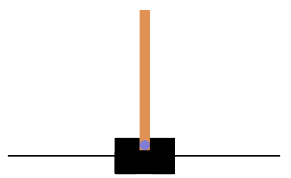

Для примера при разборе алгоритма в этот раз будем использовать среду gymnasium с **<font color='orange'>балансированием шеста на тележке CartPole</font>** (Classic Control environments). Для дальнейших алгоритмов мы будем менять среды, но также будем обсуждать вводные.

Итак, в этой среде шест прикреплен к тележке, которая движется по рельсам вправо или влево. **<font color='orange'>Цель агента</font>** - не дать шесту наклониться дальше $12°$ в сторону как можно дольше.  **<font color='orange'>Состояния </font>** описываются четырьмя характеристиками: положение тележки, скорость тележки, угол наклона шеста, угловая скорость шеста. Соответственно, у агента **<font color='orange'>два действия</font>** - толкнуть тележку влево или толкнуть тележку вправо. За каждый сделанный шаг, включая шаг завершения, выделяется **<font color='orange'>награда</font>** $r=+1$.

**<font color='orange'>Завершение эпизода</font>** происходит в трех случаях:

*   выход тележки за пределы рельс (от $-2.4$ до $2.4$);
*   наклон шеста за пределы $12°$ в любую из двух сторон (от $-0.2095$ до $0.2095$, т.е. $±12°$);
*   превышена длина эпизода: 500 шагов для среды версии v1 (200 для версии v0).


## NFQ (neural fitted Q iteration) - итерация нейронной аппроксимации Q

**<font color='orange'>NFQ</font>** - один из первых алгоритмов, который **<font color='orange'>успешно применяет аппроксимацию функций на нейросетях</font>** для задач RL. Составляющие алгоритма, которые мы здесь рассмотрим, являются составляющими **<font color='orange'>более современной версии NFQ от Моралеса</font>**. В процессе рассмотрения мы коснемся и отличий. В целом, все составляющие легко заменяемы, поэтому при необходимости можно легко собрать оригинальную версию NFQ.

Теперь разберем по пунктам составляющие алгоритма **<font color='orange'>NFQ</font>** от Моралеса. Работать будем с обновлением градиентного спуска.

### 1. Функция ценности

NFQ основан на **<font color='orange'>прогнозировании функции ценности действий $q(s,a)$</font>**. Так как мы применяем **<font color='orange'>аппроксимацию ожидаемой q-функции</font>**, то у нас будет дополнительный параметр - **<font color='orange'>вес</font>**, только здесь мы обозначим его через $θ$ а не через $w$. Он отвечает за **<font color='orange'>веса нейронной сети</font>**: $q(s,a;θ)$. Помимо функции действий можно оценивать и оценки состояний или послесостояний $v(s)$, и функцию преимущества действий $a(s)$.

<details>
<summary><b>Справка из прошлого: функции ценности</b></summary>

**<font color='orange'>Функция ценности состояния</font>** $v_π(s)$:

$$v_π(s) = \mathbb{E}_π[G_t|S_t=s] = \mathbb{E}_π[\sum_{k=0}^{\infty}γ^{k}R_{t+k+1}|S_t=s] = \sum_{a}π(a|s)q_π(s,a).$$

---

**<font color='orange'>Функция ценности действий</font>** $q_π(s,a)$:

$$q_π(s,a) = \mathbb{E}_π[G_t|S_t=s,A_t=a] = \mathbb{E}_π[\sum_{k=0}^{\infty}γ^{k}R_{t+k+1}|S_t=s,A_t=a] = \sum_{s',r}p(s',r|s,a)[r+γv_π(s')].$$

---

**<font color='orange'>Функция преимущества действия или функция преимущества, A-функция</font>**:

$$a_π(s, a) = q_π(s, a) - v_π(s).$$

Она показывает разницу между функцией ценности действия $a$ в состоянии $s$ и функцией ценности состояния $s$ при следовании $π$.

---

**<font color='orange'>Послесостояния</font>** (afterstate) $v_π(s_{after})$ — промежуточное состояние среды, в котором она оказывается сразу после действия агента, но до того, как среда вернет новое состояние (противник сделает свой ход). Специальный случай для некоторых сред, позволяющий сократить пространство состояний.
</details>


Каждая из функций хороша по своему. В дальнейшем мы посмотрим более конкретно разные варианты и влияние на строение неейросетей в алгоритмах, но общая информация следующая.

*  При испоьзовании **<font color='orange'>функции ценности состояний</font>**, как и было в табличных методах, мы получаем **<font color='orange'>информацию в целом о ценности состояния</font>**. Для решения задачи управления для определения дальнейшего действия придется еще что-то сделать.
*  Поэтому чаще также используется **<font color='orange'>функция ценности действий</font>**. В зависимости от строения сети можно получить как **<font color='orange'>оценку конкретного действия</font>**, так и **<font color='orange'>нескольких</font>**. Но если действий в каждом состоянии много, то прибегвают к третьему варианту.
*  **<font color='orange'>Функция преимущества</font>** позволит оценить, **<font color='orange'>какое действие выгоднее, по сравнению со средним</font>**.



##### Код для сравнения функций оценок

На практике в небольших табличных средах это выглядит следующим образом. Обратимся к задаче одной из прошлых методичек: МПВ с пятью состояниями.

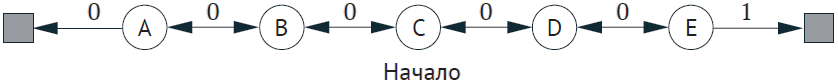

Если посчитать оценки по базовым формулам, то разница становится более понятной.


In [ ]:
import numpy as np

# 7 состояний: 0 и 6 - терминальные
n_states = 7       # 0 (левый Т), 1, 2, 3 (СТАРТ), 4, 5, 6 (правый Т)
n_actions = 2      # 0: влево, 1: вправо
gamma = 1.0

transient_states = [1, 2, 3, 4, 5]
terminal_states = [0, 6]

# Матрицы переходов P[s, a, s_next] и наград R[s, a]
P = np.zeros((n_states, n_actions, n_states))
R = np.zeros((n_states, n_actions))

for s in transient_states:
    P[s, 0, s - 1] = 1.0  # Действие 0: влево
    P[s, 1, s + 1] = 1.0  # Действие 1: вправо

    if s + 1 == 6:
        R[s, 1] = 1.0     # Награда +1 только при переходе в состояние 6

P[0, :, 0] = 1.0
P[6, :, 6] = 1.0

# Равновероятный случайный выбор (50% влево, 50% вправо)
policy = np.ones((n_states, n_actions)) * 0.5

# Оценка политики (Policy Evaluation)
P_policy = np.zeros((n_states, n_states))
R_policy = np.zeros(n_states)

for s in range(n_states):
    for a in range(n_actions):
        P_policy[s, :] += policy[s, a] * P[s, a, :]
        R_policy[s] += policy[s, a] * R[s, a]

P_trans = P_policy[1:6, 1:6]
R_trans = R_policy[1:6]

I = np.eye(len(transient_states))
V_transient = np.linalg.solve(I - gamma * P_trans, R_trans)

V = np.zeros(n_states)
V[1:6] = V_transient

# Расчет функции ценности действий Q^pi(s, a)
Q = np.zeros((n_states, n_actions))
for s in transient_states:
    for a in range(n_actions):
        s_next = s - 1 if a == 0 else s + 1
        Q[s, a] = R[s, a] + gamma * V[s_next]

# Расчет функции преимущества
Adv = np.zeros((n_states, n_actions))
for s in transient_states:
    for a in range(n_actions):
        Adv[s, a] = Q[s, a] - V[s]

# --- Вывод точных результатов ---
print("\n1. Функция ценности состояний V(s):")
for s in transient_states:
    marker = " <- СТАРТ" if s == 3 else ""
    print(f"  Состояние {s} -> V = {V[s]:.4f}{marker}")

print("\n2. Функция ценности действий Q(s, a):")
print("  Состояние | Влево (a=0) | Вправо (a=1)")
for s in transient_states:
    print(f"      {s}     |    {Q[s, 0]:.4f}    |    {Q[s, 1]:.4f}")

print("\n3. Функция преимущества Advantage A(s, a):")
print("  Состояние | Влево (a=0) | Вправо (a=1)")
for s in transient_states:
    print(f"      {s}     |   {Adv[s, 0]:.4f}   |   {Adv[s, 1]:.4f}")


1. Функция ценности состояний V(s):
  Состояние 1 -> V = 0.1667
  Состояние 2 -> V = 0.3333
  Состояние 3 -> V = 0.5000 <- СТАРТ
  Состояние 4 -> V = 0.6667
  Состояние 5 -> V = 0.8333

2. Функция ценности действий Q(s, a):
  Состояние | Влево (a=0) | Вправо (a=1)
      1     |    0.0000    |    0.3333
      2     |    0.1667    |    0.5000
      3     |    0.3333    |    0.6667
      4     |    0.5000    |    0.8333
      5     |    0.6667    |    1.0000

3. Функция преимущества Advantage A(s, a):
  Состояние | Влево (a=0) | Вправо (a=1)
      1     |   -0.1667   |   0.1667
      2     |   -0.1667   |   0.1667
      3     |   -0.1667   |   0.1667
      4     |   -0.1667   |   0.1667
      5     |   -0.1667   |   0.1667


### 2. Архитектура нейронной сети

**<font color='orange'>Архитектура нейронной сети</font>** для прогнозировании функции ценности действий обычно применяется двух видов.

1.   **<font color='orange'>"Состояние-действие на входе, значение на выходе"</font>**. На вход подаем состояние $s$ и действие $a$, а на выходе нейронной сети получаем оценку.
2.   **<font color='orange'>"Состояние на входе, значения на выходе"</font>**. На вход подаем состояние $s$, а на выходе получаем оценки действий $a$. Естественно, у нас **<font color='orange'>застабилизированно количество нейронов входного и выходного слоя</font>**, т.е. в этом случае у нас должно быть конечное число действий.

Помимо того, что количество действий во втором случае должно быть дискретно и стабильно, есть еще **<font color='orange'>ряд проблем</font>**. В их числе: проблемы при комбинации действий (касается задач, где агент управляет несколькими вещами, например, выравнивает температуру и следит за влажностью), проблемы с интеграцией послесостояний, смещение максимизации, сложности с обобщением опыта для похожих действий. Поэтому чаще **<font color='orange'>в крупных алгоритмах используется первый вариант</font>**.

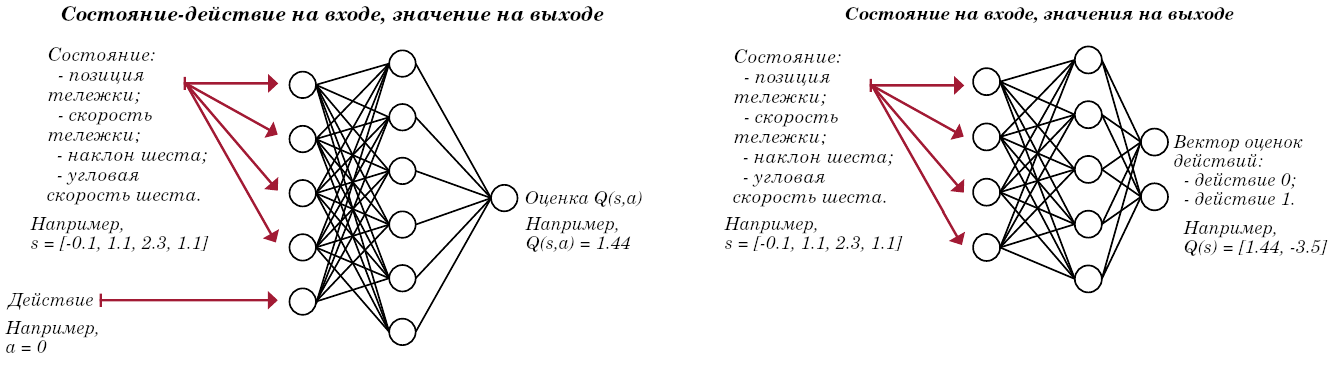

В нашем случае, так как действий стабильное количество (всего два) и среда CartPole относительно простая, то мы будем использовать **<font color='orange'>второй вариант</font>**. В предложенной реализации вся нейронная сеть будет состоять из нескольких полносвязный слоев nn.Linear(...).

Естественно, в более сложных средах и алгоритмах будет изменяться не только строение входного и выходного слоев, но и **<font color='orange'>внутренние слои, их количество и вид</font>**.

### 3. Функция оптимизации

Теперь определимся с выбором **<font color='orange'>функции для оптимизации</font>**. Обычно все **<font color='orange'>нейронные сети отталкиваются от правильного ответа</font>**, т.е. в нашем случае от оптимальной оценки $q^*(s,a)$. Т.е. в **<font color='orange'>идеальном случае мы хотим минимизировать</font>** $(q^*(s,a) - q(s,a;θ_i))^2$.

Но у нас **<font color='orange'>$q^*(s,a)$ нет</font>**. Зато мы можем использовать ОИС, **<font color='orange'>чередуя операции оценки и улучшения стратегии</font>**. Тогда можно отталкиваться от того, что получили в качестве дохода плюс оценка следующего состояния и сравнивать с тем, какая оценка этому состоянию была назначена в прошлый раз. Таким образом, оптимизировать будем $q(s,a;θ)$ для аппроксимации ее оптимальной версии $q^*(s,a)$.

Но тут **<font color='orange'>важно помнить, что гарантии сходимости в этом случае у нас отсутствуют</font>**, потому что мы аппроксимируем нелинейную функцию.

### 4. Цель для оценки

Далее идет выбор **<font color='orange'>цели для оценки политики</font>**. Под этим подразумевается те самые изученные нами методы: **<font color='orange'>МК, TD, n-шаговые версии и далее</font>**. В данной реализации мы будем использовать простой одношаговый вариант Q-learning: $(R_{t+1}+γmax_aq(S_{t+1}, a;θ_i))$.

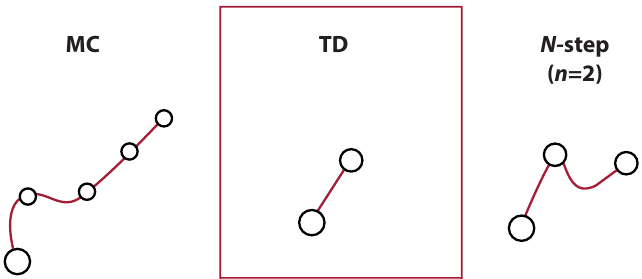

Возвращаясь к функции обучения нейронной сети, мы можем сформировать **<font color='orange'>цель на основе полученной награды и следующего состояния</font>** $(r+γmax_{a'}q(s', a';θ_i) - q(s, a;θ_i))^2$. Перейдем к **<font color='orange'>градиенту</font>** $(r+γmax_{a'}q(s', a';θ_i) - q(s, a;θ_i))∇_{θ_i}q(s, a;θ_i)$.

### 5. Исследовательская стратегия

После этого мы должны определиться с **<font color='orange'>исследовательской стратегией</font>**. Так как **<font color='orange'>конфликт исследования-использования</font>** никуда не делся, необходимо добавлять исследование и контролировать его долю.

В нашей реализации будем пользоваться **<font color='orange'>$ε$-жадной стратегией</font>** с $ε=0.5$. Необычный выбор, обычно $ε<0.5$. Далее сможем в коде самостоятельно повыбирать параметры, в том числе этот, и сравнить получаемые результаты.

### 6. Loss-функция для нейронной сети

**<font color='orange'>Функцию потерь для нейронной сети (loss-функцию)</font>** возьмем из стандартного пула, который частично был пройден на курсе "Большие данные".

Здесь это будет **<font color='orange'>MSE (mean squared error)</font>** - среднеквадратичная ошибка. В данном случае в качестве **<font color='orange'>прогнозируемого значения</font>** выступает **<font color='orange'>q-функция из нейросети</font>**, а в качестве **<font color='orange'>реальных значений</font>** мы используем **<font color='orange'>TD-цель</font>** из Q-обучения. Позднее мы посмотрим на проблемы, которые это приносит, так как эти **<font color='orange'>цели также прогнозируются через ту же нейросеть</font>**.

### 7. Метод оптимизации для минимизации loss-функции

И, наконец, выбираем **<font color='orange'>метод оптимизации для минимизации функции потерь</font>**. Существует много вариантов, как организовать **<font color='orange'>градиентный спуск</font>**. Тут и пакетный градиентный спуск (А), и мини-пакетный градиентный спуск (Б), и стохастический градиентный спуск (В), и инерция или RMSprop (Г пунктир). Чаще всего за счет маленького объема мини-пакетный градиентный спуск часто выглядит зигзагообразно (Г сплошная линия).

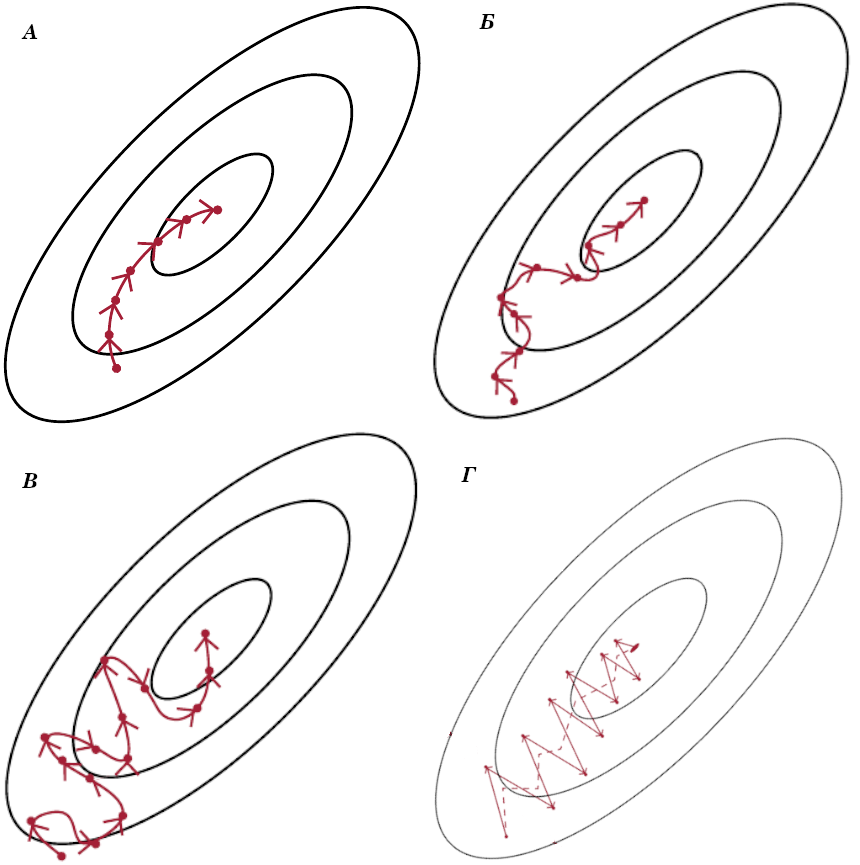

Будем использовать мини-пакетный градиентный спуск (mini-batch SGD) и надежный и простой **<font color='orange'>RMSprop с темпом обучения 0.0005</font>**.

Помимо RMSprop в данном случае также подходит и **<font color='orange'>Adam</font>**. Он пошагово приближается к вектору движения градиентов (инерция), но масштабирует обновления прямо пропорционально скользящему среднему магнитуды градиентов (RMSprop). Это некоторая середина между инерцией и RMSprop.

Основная **<font color='orange'>проблема с градиентным спуском</font>** состоит в том, что для его использования наши данные должны быть **<font color='orange'>независимы</font>** и **<font color='orange'>одинаково распределены</font>**, а **<font color='orange'>цели</font>** должны быть **<font color='orange'>стационарны</font>**. Но в **<font color='orange'>DRL нельзя гарантировать выполнения ни одного из этих условий</font>**. Поэтому седьмой пункт очень важен, так как от него зависит **<font color='orange'>достижение сходимости</font>**.

### Что получилось в сумме

1. Аппроксимация $q(s,a;θ)$.
2. Архитектура "состояние на входе, значения на выходе".
3. Оптимизация q-функции дляя аппрокимайии $q^*(s,a)$.
4. Цель для оценки политики $(r+γmax_{a'}q(s', a';θ_i))$.
5. Исследовательская $𝜀$-жадная политика с $𝜀 = 0.5$.
6. MSE.
7. мини-пакетный ГС с RMSprop с темпом обучения $0.0005$.

По сравнению с исходным видом NFQ 2005 года от Мартина Ридмиллера, **<font color='orange'>основные отличия</font>** состоят в архитектуре нейросети (базово была состояние-действие на входе, значение на выходе), случайной исследовательской политики (random), пакетный метод с полной выборкой с Rprop. Таким образом, для исходного алгоритма необходимо **<font color='orange'>полностью собрать набор данных</font>** для обучения и работать с ним **<font color='orange'>без изменений</font>** в течении обучения (offline), прием сразу со **<font color='orange'>всем набором</font>**. В предложенной версии адаптирована возможность **<font color='orange'>активного взаимодействия со средой</font>** (онлайн-сбор, online sampling) и обучение по **<font color='orange'>мини-выборке</font>** из полученного набора данных. Фактически, версия NFQ от Моралеса напоминает DQN (будет разобран позже).

## Общий алгоритм NFQ

**<font color='orange'>NFQ действует следующим образом</font>**:

1.   Собираем Е шагов опыта: $(s,a,r,s',done)$ кортежи; в текущей реализации собираем 1024 штуки таких кортежей.
2.   Расчитываем off-policy TD цель (Q-обучение): $R_{t+1} + γ\ max_aQ(S_{t+1}, a;θ)$.
3.   Обучаем нашу функцию ценности действий $Q(s,a;θ)$ с помощью MSE и RMSprop.

Причем 2 и 3 шаги повторяются $K$ раз перед переходом снова к 1 шагу. В текущей реализации $K=40$.



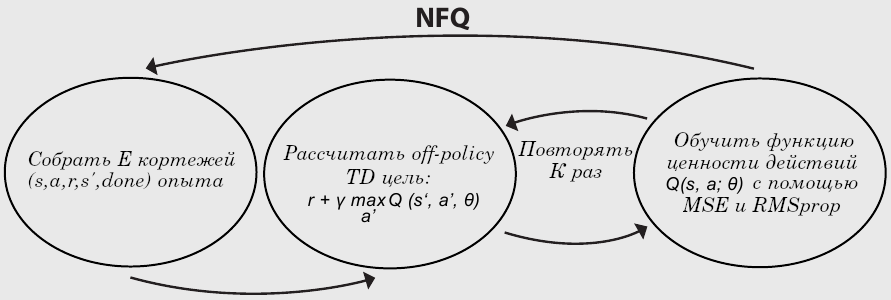

## Код для NFQ

Не забудьте в Google.Colaboratory во вкладке Среда выполнения Сменить среду выполнения с CPU на GPU (T4GPU). Если есть возможность, естественно. В противном случае, если хотите только посмотреть в целом алгоритм, рекомендуется сократить число эпох, модифицировав строчку:

```python
# Задание "зерна" генерации для 1 эпохи обучения
SEEDS = (12, )
```

В противном случае время обучения будет достаточно большим.


In [ ]:
!nvidia-smi

Thu Aug 29 10:41:50 2024       
+---------------------------------------------------------------------------------------+
| NVIDIA-SMI 535.104.05             Driver Version: 535.104.05   CUDA Version: 12.2     |
|-----------------------------------------+----------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id        Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |         Memory-Usage | GPU-Util  Compute M. |
|                                         |                      |               MIG M. |
|=========================================+======================+======================|
|   0  Tesla T4                       Off | 00000000:00:04.0 Off |                    0 |
| N/A   69C    P8              10W /  70W |      0MiB / 15360MiB |      0%      Default |
|                                         |                      |                  N/A |
+-----------------------------------------+----------------------+--

In [ ]:
import warnings ; warnings.filterwarnings('ignore')
import os

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

import numpy as np
from IPython.display import display
from collections import namedtuple, deque
import matplotlib.pyplot as plt
import matplotlib.pylab as pylab
from itertools import cycle, count
from textwrap import wrap

import matplotlib
import subprocess
import os.path
import tempfile
import random
import base64
import pprint
import glob
import time
import json
import sys
import gym
import io
import os
import gc

from gym import wrappers
from subprocess import check_output
from IPython.display import HTML

LEAVE_PRINT_EVERY_N_SECS = 60
ERASE_LINE = '\x1b[2K'
EPS = 1e-6
BEEP = lambda: os.system("printf '\a'")
RESULTS_DIR = os.path.join('..', 'results')

# Задание "зерна" генерации для 5 эпох обучения
SEEDS = (12, 34, 56, 78, 90)

%matplotlib inline

In [ ]:
%%bash
# install required system dependencies
apt-get install -y xvfb x11-utils
# install required python dependencies
pip install gym[CartPole-v1]==0.17.* \
            pyvirtualdisplay==0.2.* \
            PyOpenGL==3.1.* \
            PyOpenGL-accelerate==3.1.*

pip install piglet
apt-get install imagemagick

/usr/local/lib/python3.10/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


Reading package lists...
Building dependency tree...
Reading state information...
The following additional packages will be installed:
  libfontenc1 libxfont2 libxkbfile1 libxtst6 libxxf86dga1 x11-xkb-utils xfonts-base
  xfonts-encodings xfonts-utils xserver-common
Suggested packages:
  mesa-utils
The following NEW packages will be installed:
  libfontenc1 libxfont2 libxkbfile1 libxtst6 libxxf86dga1 x11-utils x11-xkb-utils xfonts-base
  xfonts-encodings xfonts-utils xserver-common xvfb
0 upgraded, 12 newly installed, 0 to remove and 49 not upgraded.
Need to get 8,045 kB of archives.
After this operation, 12.8 MB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu jammy/main amd64 libfontenc1 amd64 1:1.1.4-1build3 [14.7 kB]
Get:2 http://archive.ubuntu.com/ubuntu jammy/main amd64 libxfont2 amd64 1:2.0.5-1build1 [94.5 kB]
Get:3 http://archive.ubuntu.com/ubuntu jammy/main amd64 libxkbfile1 amd64 1:1.1.0-1build3 [71.8 kB]
Get:4 http://archive.ubuntu.com/ubuntu jamm

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
bigframes 1.15.0 requires cloudpickle>=2.0.0, but you have cloudpickle 1.6.0 which is incompatible.


In [ ]:
# Для графиков
plt.style.use('fivethirtyeight')
params = {
    'figure.figsize': (15, 8),
    'font.size': 24,
    'legend.fontsize': 20,
    'axes.titlesize': 28,
    'axes.labelsize': 24,
    'xtick.labelsize': 20,
    'ytick.labelsize': 20
}
pylab.rcParams.update(params)
np.set_printoptions(suppress=True)

/usr/local/lib/python3.10/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


In [ ]:
# Проверяем подключение GPU
torch.cuda.is_available()

/usr/local/lib/python3.10/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


True

In [ ]:
def get_make_env_fn(**kargs):
    def make_env_fn(env_name, seed=None, render=None, record=False,
                    unwrapped=False, monitor_mode=None,
                    inner_wrappers=None, outer_wrappers=None):
        mdir = tempfile.mkdtemp()
        env = None
        if render:
            try:
                env = gym.make(env_name, render=render)
            except:
                pass
        if env is None:
            env = gym.make(env_name)
        if seed is not None: env.seed(seed)
        env = env.unwrapped if unwrapped else env
        if inner_wrappers:
            for wrapper in inner_wrappers:
                env = wrapper(env)
        if outer_wrappers:
            for wrapper in outer_wrappers:
                env = wrapper(env)
        return env
    return make_env_fn, kargs

## NFQ

In [ ]:
# Нейронная сеть
class FCQ(nn.Module):
    def __init__(self,
                 input_dim,
                 output_dim,
                 hidden_dims=(32,32),
                 activation_fc=F.relu):
        super(FCQ, self).__init__()
        self.activation_fc = activation_fc

        # В этом варианте сеть состоить только из простых полносвязных слоев
        # Входной слой
        self.input_layer = nn.Linear(input_dim, hidden_dims[0])
        # Скрытые слои # (512,128) -> 2 слоя из 512 и 128 нейронов соответственно
        self.hidden_layers = nn.ModuleList()
        for i in range(len(hidden_dims)-1):
            hidden_layer = nn.Linear(hidden_dims[i], hidden_dims[i+1])
            self.hidden_layers.append(hidden_layer)
        # Выходной слой
        self.output_layer = nn.Linear(hidden_dims[-1], output_dim)

        device = "cpu"
        if torch.cuda.is_available():
            device = "cuda:0"
        self.device = torch.device(device)
        self.to(self.device)

    #  Проверяем, чтобы на вход шли только тензоры
    def _format(self, state):
        x = state
        if not isinstance(x, torch.Tensor):
            x = torch.tensor(x,
                             device=self.device,
                             dtype=torch.float32)
            x = x.unsqueeze(0)
        return x

    def forward(self, state):
        x = self._format(state)

        # Пропускаем данные состояния через нейронную сеть
        x = self.activation_fc(self.input_layer(x))
        for hidden_layer in self.hidden_layers:
            x = self.activation_fc(hidden_layer(x))
        x = self.output_layer(x)
        return x

    # Загружаем данные
    def load(self, experiences):
        states, actions, new_states, rewards, is_terminals = experiences
        states = torch.from_numpy(states).float().to(self.device)
        actions = torch.from_numpy(actions).long().to(self.device)
        new_states = torch.from_numpy(new_states).float().to(self.device)
        rewards = torch.from_numpy(rewards).float().to(self.device)
        is_terminals = torch.from_numpy(is_terminals).float().to(self.device)
        return states, actions, new_states, rewards, is_terminals

In [ ]:
# жадная стратегия
class GreedyStrategy():
    def __init__(self):
        self.exploratory_action_taken = False

    # Работаем с пакетом данных
    def select_action(self, model, state):
        with torch.no_grad():
            q_values = model(state).cpu().detach().data.numpy().squeeze()
            return np.argmax(q_values)

In [ ]:
# e-жадная стратегия
class EGreedyStrategy():
    def __init__(self, epsilon=0.1):
        self.epsilon = epsilon
        self.exploratory_action_taken = None

    # Работаем с пакетом данных
    def select_action(self, model, state):
        self.exploratory_action_taken = False
        with torch.no_grad():
            q_values = model(state).cpu().detach().data.numpy().squeeze()

        if np.random.rand() > self.epsilon:
            action = np.argmax(q_values)
        else:
            action = np.random.randint(len(q_values))

        self.exploratory_action_taken = action != np.argmax(q_values)
        return action

In [ ]:
class NFQ():
    def __init__(self,
                 value_model_fn,
                 value_optimizer_fn,
                 value_optimizer_lr,
                 training_strategy_fn,
                 evaluation_strategy_fn,
                 batch_size,
                 epochs):
        self.value_model_fn = value_model_fn
        self.value_optimizer_fn = value_optimizer_fn
        self.value_optimizer_lr = value_optimizer_lr
        self.training_strategy_fn = training_strategy_fn
        self.evaluation_strategy_fn = evaluation_strategy_fn
        self.batch_size = batch_size
        self.epochs = epochs

    # Оптимизация модели и нейросети
    def optimize_model(self, experiences):
        states, actions, rewards, next_states, is_terminals = experiences
        batch_size = len(is_terminals)

        # Вычисляем через цель обучения максимальное значение следующего состояния
        max_a_q_sp = self.online_model(next_states).detach().max(1)[0].unsqueeze(1)
        # Вычисляем цель обучения с проверкой: не является ли next_state конечным состоянием
        target_q_s = rewards + self.gamma * max_a_q_sp * (1 - is_terminals)
        # Получаем текущий прогноз Q(s,a)
        q_sa = self.online_model(states).gather(1, actions)

        # Находим td-ошибку
        td_errors = q_sa - target_q_s
        # Обучаем нейросеть
        value_loss = td_errors.pow(2).mul(0.5).mean()
        self.value_optimizer.zero_grad()
        value_loss.backward()
        self.value_optimizer.step()

    # Взаимодействие со средой
    def interaction_step(self, state, env):
        # Выбираем действие
        action = self.training_strategy.select_action(self.online_model, state)
        # Отправляем действие в среду
        new_state, reward, is_terminal, info = env.step(action)
        # Проверяем ошибки, окончание времени и окончание эпизода
        is_truncated = 'TimeLimit.truncated' in info and info['TimeLimit.truncated']
        is_failure = is_terminal and not is_truncated
        # Формируем  и сохраняем данные
        experience = (state, action, reward, new_state, float(is_failure))

        self.experiences.append(experience)
        self.episode_reward[-1] += reward
        self.episode_timestep[-1] += 1
        self.episode_exploration[-1] += int(self.training_strategy.exploratory_action_taken)
        return new_state, is_terminal

    def train(self, make_env_fn, make_env_kargs, seed, gamma,
              max_minutes, max_episodes, goal_mean_100_reward):
        training_start, last_debug_time = time.time(), float('-inf')

        self.checkpoint_dir = tempfile.mkdtemp()
        self.make_env_fn = make_env_fn
        self.make_env_kargs = make_env_kargs
        self.seed = seed
        self.gamma = gamma

        # Собираем среду и задаем начальные зерна генерации
        env = self.make_env_fn(**self.make_env_kargs, seed=self.seed)
        torch.manual_seed(self.seed) ; np.random.seed(self.seed) ; random.seed(self.seed)

        nS, nA = env.observation_space.shape[0], env.action_space.n
        self.episode_timestep = []
        self.episode_reward = []
        self.episode_seconds = []
        self.evaluation_scores = []
        self.episode_exploration = []

        # Создаем нейросеть
        self.online_model = self.value_model_fn(nS, nA)
        self.value_optimizer = self.value_optimizer_fn(self.online_model,
                                                       self.value_optimizer_lr)

        self.training_strategy = training_strategy_fn()
        self.evaluation_strategy = evaluation_strategy_fn()
        self.experiences = []

        result = np.empty((max_episodes, 5))
        result[:] = np.nan
        training_time = 0

        # Начинаем обучение
        for episode in range(1, max_episodes + 1):
            episode_start = time.time()

            state, is_terminal = env.reset(), False
            self.episode_reward.append(0.0)
            self.episode_timestep.append(0.0)
            self.episode_exploration.append(0.0)

            for step in count():
                state, is_terminal = self.interaction_step(state, env)

                # Собираем пакет опыта
                if len(self.experiences) >= self.batch_size:
                    experiences = np.array(self.experiences, dtype="object")
                    batches = [np.vstack(sars) for sars in experiences.T]
                    experiences = self.online_model.load(batches)
                    # Улучшаем нейронную сеть
                    for _ in range(self.epochs):
                        self.optimize_model(experiences)
                    self.experiences.clear()

                if is_terminal:
                    gc.collect()
                    break

            # Статистика и промежуточные результаты
            episode_elapsed = time.time() - episode_start
            self.episode_seconds.append(episode_elapsed)
            training_time += episode_elapsed
            evaluation_score, _ = self.evaluate(self.online_model, env)
            self.save_checkpoint(episode-1, self.online_model)

            total_step = int(np.sum(self.episode_timestep))
            self.evaluation_scores.append(evaluation_score)

            mean_10_reward = np.mean(self.episode_reward[-10:])
            std_10_reward = np.std(self.episode_reward[-10:])
            mean_100_reward = np.mean(self.episode_reward[-100:])
            std_100_reward = np.std(self.episode_reward[-100:])
            mean_100_eval_score = np.mean(self.evaluation_scores[-100:])
            std_100_eval_score = np.std(self.evaluation_scores[-100:])
            lst_100_exp_rat = np.array(
                self.episode_exploration[-100:])/np.array(self.episode_timestep[-100:])
            mean_100_exp_rat = np.mean(lst_100_exp_rat)
            std_100_exp_rat = np.std(lst_100_exp_rat)

            wallclock_elapsed = time.time() - training_start
            result[episode-1] = total_step, mean_100_reward, \
                mean_100_eval_score, training_time, wallclock_elapsed

            reached_debug_time = time.time() - last_debug_time >= LEAVE_PRINT_EVERY_N_SECS
            reached_max_minutes = wallclock_elapsed >= max_minutes * 60
            reached_max_episodes = episode >= max_episodes
            reached_goal_mean_reward = mean_100_eval_score >= goal_mean_100_reward
            training_is_over = reached_max_minutes or \
                               reached_max_episodes or \
                               reached_goal_mean_reward

            elapsed_str = time.strftime("%H:%M:%S", time.gmtime(time.time() - training_start))
            debug_message = 'el {}, ep {:04}, ts {:06}, '
            debug_message += 'ar 10 {:05.1f}\u00B1{:05.1f}, '
            debug_message += '100 {:05.1f}\u00B1{:05.1f}, '
            debug_message += 'ex 100 {:02.1f}\u00B1{:02.1f}, '
            debug_message += 'ev {:05.1f}\u00B1{:05.1f}'
            debug_message = debug_message.format(
                elapsed_str, episode-1, total_step, mean_10_reward, std_10_reward,
                mean_100_reward, std_100_reward, mean_100_exp_rat, std_100_exp_rat,
                mean_100_eval_score, std_100_eval_score)
            print(debug_message, end='\r', flush=True)
            if reached_debug_time or training_is_over:
                print(ERASE_LINE + debug_message, flush=True)
                last_debug_time = time.time()
            if training_is_over:
                if reached_max_minutes: print(u'--> reached_max_minutes \u2715')
                if reached_max_episodes: print(u'--> reached_max_episodes \u2715')
                if reached_goal_mean_reward: print(u'--> reached_goal_mean_reward \u2713')
                break

        final_eval_score, score_std = self.evaluate(self.online_model, env, n_episodes=100)
        wallclock_time = time.time() - training_start
        print('Training complete.')
        print('Final evaluation score {:.2f}\u00B1{:.2f} in {:.2f}s training time,'
              ' {:.2f}s wall-clock time.\n'.format(
                  final_eval_score, score_std, training_time, wallclock_time))
        env.close() ; del env
        self.get_cleaned_checkpoints()
        return result, final_eval_score, training_time, wallclock_time

    # Оцениваем, насколько хорошо обучилась нейросеть
    def evaluate(self, eval_policy_model, eval_env, n_episodes=1):
        rs = []
        for _ in range(n_episodes):
            s, d = eval_env.reset(), False
            rs.append(0)
            for _ in count():
                a = self.evaluation_strategy.select_action(eval_policy_model, s)
                s, r, d, _ = eval_env.step(a)
                rs[-1] += r
                if d: break
        return np.mean(rs), np.std(rs)

    def get_cleaned_checkpoints(self, n_checkpoints=5):
        try:
            return self.checkpoint_paths
        except AttributeError:
            self.checkpoint_paths = {}

        paths = glob.glob(os.path.join(self.checkpoint_dir, '*.tar'))
        paths_dic = {int(path.split('.')[-2]):path for path in paths}
        last_ep = max(paths_dic.keys())
        checkpoint_idxs = np.linspace(1, last_ep+1, n_checkpoints, endpoint=True, dtype=int)-1

        for idx, path in paths_dic.items():
            if idx in checkpoint_idxs:
                self.checkpoint_paths[idx] = path
            else:
                os.unlink(path)

        return self.checkpoint_paths

    def save_checkpoint(self, episode_idx, model):
        torch.save(model.state_dict(),
                   os.path.join(self.checkpoint_dir, 'model.{}.tar'.format(episode_idx)))

In [ ]:
nfq_results = []
best_agent, best_eval_score = None, float('-inf')
for seed in SEEDS:
    # Настройка среды
    environment_settings = {
        'env_name': 'CartPole-v1',
        'gamma': 1.00,
        'max_minutes': 20,
        'max_episodes': 10000,
        'goal_mean_100_reward': 475
    }

    # Нейронная сеть
    value_model_fn = lambda nS, nA: FCQ(nS, nA, hidden_dims=(512,128))
    # value_optimizer_fn = lambda net, lr: optim.Adam(net.parameters(), lr=lr)
    value_optimizer_fn = lambda net, lr: optim.RMSprop(net.parameters(), lr=lr)
    value_optimizer_lr = 0.0005

    # Стратегии принятия решений
    training_strategy_fn = lambda: EGreedyStrategy(epsilon=0.5)
    # evaluation_strategy_fn = lambda: EGreedyStrategy(epsilon=0.05)
    evaluation_strategy_fn = lambda: GreedyStrategy()

    # Размер пакета и количество эпизодов в эпохе обучения
    batch_size = 1024
    epochs = 40

    env_name, gamma, max_minutes, \
    max_episodes, goal_mean_100_reward = environment_settings.values()
    agent = NFQ(value_model_fn,
                value_optimizer_fn,
                value_optimizer_lr,
                training_strategy_fn,
                evaluation_strategy_fn,
                batch_size,
                epochs)

    make_env_fn, make_env_kargs = get_make_env_fn(env_name=env_name)
    result, final_eval_score, training_time, wallclock_time = agent.train(
        make_env_fn, make_env_kargs, seed, gamma, max_minutes, max_episodes, goal_mean_100_reward)
    nfq_results.append(result)
    if final_eval_score > best_eval_score:
        best_eval_score = final_eval_score
        best_agent = agent
nfq_results = np.array(nfq_results)
_ = BEEP()

/usr/local/lib/python3.10/dist-packages/gym/core.py:317: DeprecationWarning: WARN: Initializing wrapper in old step API which returns one bool instead of two. It is recommended to set `new_step_api=True` to use new step API. This will be the default behaviour in future.
/usr/local/lib/python3.10/dist-packages/gym/wrappers/step_api_compatibility.py:39: DeprecationWarning: WARN: Initializing environment in old step API which returns one bool instead of two. It is recommended to set `new_step_api=True` to use new step API. This will be the default behaviour in future.


el 00:00:01, ep 0000, ts 000017, ar 10 017.0±000.0, 100 017.0±000.0, ex 100 0.4±0.0, ev 009.0±000.0


/usr/local/lib/python3.10/dist-packages/gym/utils/passive_env_checker.py:227: DeprecationWarning: WARN: Core environment is written in old step API which returns one bool instead of two. It is recommended to rewrite the environment with new step API. 
/usr/local/lib/python3.10/dist-packages/gym/utils/passive_env_checker.py:233: DeprecationWarning: `np.bool8` is a deprecated alias for `np.bool_`.  (Deprecated NumPy 1.24)


el 00:01:01, ep 0431, ts 007625, ar 10 021.2±005.9, 100 015.5±006.4, ex 100 0.2±0.1, ev 013.2±006.0
el 00:02:02, ep 0869, ts 024627, ar 10 054.5±032.5, 100 063.6±048.6, ex 100 0.3±0.1, ev 104.2±070.4
el 00:03:02, ep 1282, ts 040650, ar 10 022.8±004.9, 100 034.8±035.2, ex 100 0.3±0.1, ev 078.8±053.8
el 00:04:02, ep 1619, ts 058754, ar 10 091.9±049.8, 100 076.7±051.9, ex 100 0.3±0.1, ev 133.6±020.6
el 00:05:02, ep 1929, ts 083591, ar 10 100.2±055.8, 100 122.8±067.3, ex 100 0.3±0.1, ev 237.0±083.9
el 00:06:02, ep 2162, ts 113362, ar 10 168.8±103.8, 100 140.3±086.4, ex 100 0.3±0.1, ev 322.1±089.5
el 00:07:02, ep 2344, ts 142008, ar 10 195.2±172.2, 100 174.1±136.0, ex 100 0.3±0.1, ev 435.2±078.0
el 00:08:02, ep 2481, ts 165075, ar 10 114.2±104.0, 100 169.6±124.4, ex 100 0.3±0.1, ev 399.2±108.1
el 00:09:02, ep 2652, ts 190851, ar 10 160.8±094.2, 100 150.5±124.7, ex 100 0.3±0.1, ev 415.6±102.1
el 00:09:59, ep 2818, ts 218886, ar 10 159.0±113.8, 100 167.3±120.1, ex 100 0.3±0.1, ev 475.7±053.7


/usr/local/lib/python3.10/dist-packages/gym/core.py:317: DeprecationWarning: WARN: Initializing wrapper in old step API which returns one bool instead of two. It is recommended to set `new_step_api=True` to use new step API. This will be the default behaviour in future.
/usr/local/lib/python3.10/dist-packages/gym/wrappers/step_api_compatibility.py:39: DeprecationWarning: WARN: Initializing environment in old step API which returns one bool instead of two. It is recommended to set `new_step_api=True` to use new step API. This will be the default behaviour in future.


el 00:01:00, ep 0516, ts 010212, ar 10 022.1±004.5, 100 020.5±007.6, ex 100 0.2±0.1, ev 017.6±002.4
el 00:02:00, ep 0875, ts 033325, ar 10 081.6±027.8, 100 096.2±054.1, ex 100 0.3±0.1, ev 203.2±103.8
el 00:03:00, ep 1097, ts 061567, ar 10 130.1±096.2, 100 149.5±101.5, ex 100 0.3±0.1, ev 375.9±098.6
el 00:04:00, ep 1326, ts 091066, ar 10 103.8±092.4, 100 121.2±093.1, ex 100 0.3±0.1, ev 283.7±116.0
el 00:05:01, ep 1537, ts 120877, ar 10 136.8±105.7, 100 143.5±083.5, ex 100 0.3±0.1, ev 311.8±104.3
el 00:06:01, ep 1726, ts 150411, ar 10 102.4±091.9, 100 152.6±122.5, ex 100 0.3±0.1, ev 433.7±090.0
el 00:07:01, ep 1916, ts 182231, ar 10 165.0±145.3, 100 168.8±124.9, ex 100 0.3±0.1, ev 443.4±090.2
el 00:08:01, ep 2111, ts 212303, ar 10 088.1±048.4, 100 158.1±106.6, ex 100 0.3±0.1, ev 425.1±100.2
el 00:09:01, ep 2307, ts 241543, ar 10 149.3±093.1, 100 148.0±100.8, ex 100 0.3±0.1, ev 411.1±110.0
el 00:10:01, ep 2496, ts 273429, ar 10 107.0±055.6, 100 170.3±114.8, ex 100 0.3±0.0, ev 386.2±120.2


На Tesla T4 одна эпоха обучения занимает ~11 минут.

~55 минут на 5 эпох. А без будет CUDA еще медленнее будет.

In [ ]:
nfq_max_t, nfq_max_r, nfq_max_s, \
    nfq_max_sec, nfq_max_rt = np.max(nfq_results, axis=0).T
nfq_min_t, nfq_min_r, nfq_min_s, \
    nfq_min_sec, nfq_min_rt = np.min(nfq_results, axis=0).T
nfq_mean_t, nfq_mean_r, nfq_mean_s, \
    nfq_mean_sec, nfq_mean_rt = np.mean(nfq_results, axis=0).T
nfq_x = np.arange(len(nfq_mean_s))

/usr/local/lib/python3.10/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


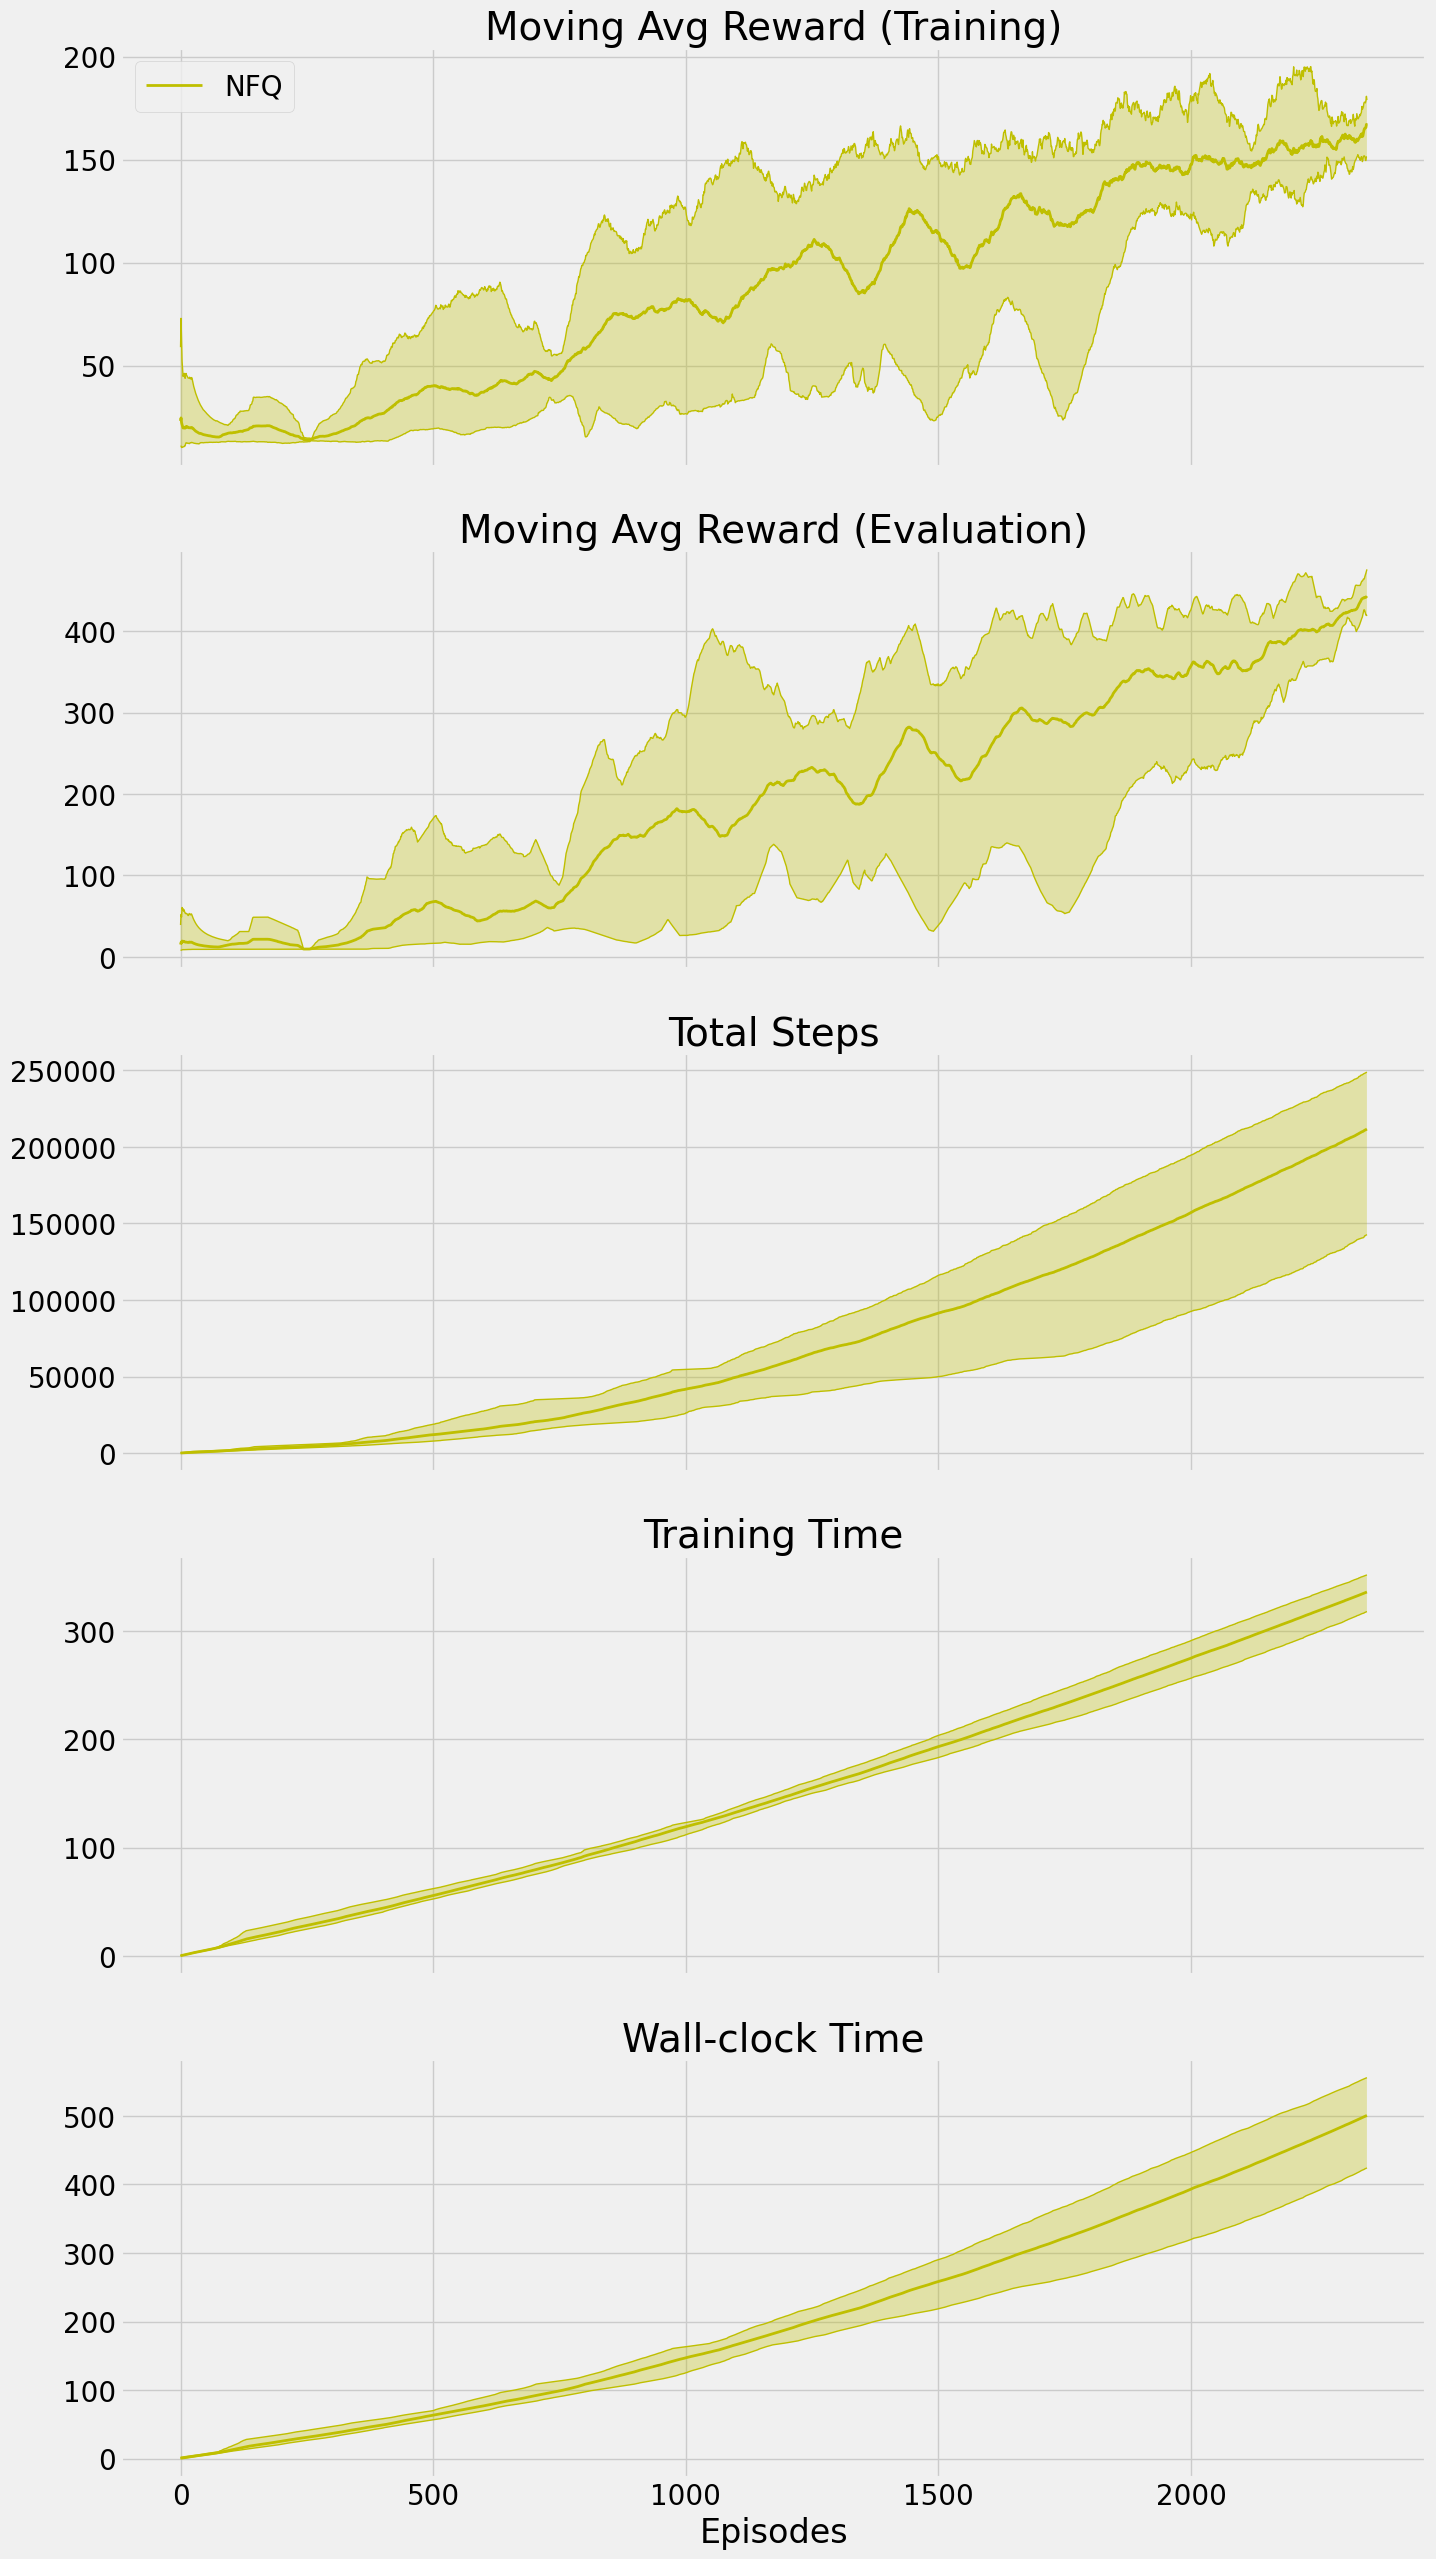

In [ ]:
fig, axs = plt.subplots(5, 1, figsize=(15,30), sharey=False, sharex=True)

# NFQ
axs[0].plot(nfq_max_r, 'y', linewidth=1)
axs[0].plot(nfq_min_r, 'y', linewidth=1)
axs[0].plot(nfq_mean_r, 'y', label='NFQ', linewidth=2)
axs[0].fill_between(nfq_x, nfq_min_r, nfq_max_r, facecolor='y', alpha=0.3)

axs[1].plot(nfq_max_s, 'y', linewidth=1)
axs[1].plot(nfq_min_s, 'y', linewidth=1)
axs[1].plot(nfq_mean_s, 'y', label='NFQ', linewidth=2)
axs[1].fill_between(nfq_x, nfq_min_s, nfq_max_s, facecolor='y', alpha=0.3)

axs[2].plot(nfq_max_t, 'y', linewidth=1)
axs[2].plot(nfq_min_t, 'y', linewidth=1)
axs[2].plot(nfq_mean_t, 'y', label='NFQ', linewidth=2)
axs[2].fill_between(nfq_x, nfq_min_t, nfq_max_t, facecolor='y', alpha=0.3)

axs[3].plot(nfq_max_sec, 'y', linewidth=1)
axs[3].plot(nfq_min_sec, 'y', linewidth=1)
axs[3].plot(nfq_mean_sec, 'y', label='NFQ', linewidth=2)
axs[3].fill_between(nfq_x, nfq_min_sec, nfq_max_sec, facecolor='y', alpha=0.3)

axs[4].plot(nfq_max_rt, 'y', linewidth=1)
axs[4].plot(nfq_min_rt, 'y', linewidth=1)
axs[4].plot(nfq_mean_rt, 'y', label='NFQ', linewidth=2)
axs[4].fill_between(nfq_x, nfq_min_rt, nfq_max_rt, facecolor='y', alpha=0.3)

# ALL
axs[0].set_title('Moving Avg Reward (Training)')
axs[1].set_title('Moving Avg Reward (Evaluation)')
axs[2].set_title('Total Steps')
axs[3].set_title('Training Time')
axs[4].set_title('Wall-clock Time')
plt.xlabel('Episodes')
axs[0].legend(loc='upper left')
plt.show()

#### Обсуждение 3


1. Выберите среду из gymnasium (например, Frozen Lake или Taxi) и адаптируйте для нее NFQ. Сравните результаты обучения в зависимости от изменения гиперпараметров (например, измените $ε$ и сравните обучение при $ε = {0.5, 0.3, 0.1}$; измените размер пакета и количество эпизодов в эпохе обучения; измените $γ$ и $α$). Можно брать среду из проекта за прошлый семестр.

#### Подсказки 3

1.   Берем опорный код NFQ, меняем под свою среду или пишем свой вариант и строим графики для сравнения.